# Emergencias y daños por peligros naturales en la región Puno (2003-2026)
## Analítica descriptiva, diagnóstica, predictiva y prescriptiva con datos del SINPAD-INDECI

**Curso:** Business Intelligence and Data Analytics · Maestría en Informática, EPG-UNA Puno · Semana 4
**Docente:** Dr. Fred Torres Cruz
**Estudiante:** Mary Luz Nina Palacios

**Fuente:** Instituto Nacional de Defensa Civil (INDECI), *Emergencias y daños a nivel nacional por departamento*,
Plataforma Nacional de Datos Abiertos (datosabiertos.gob.pe). Recursos: `BD_2003-2025_EMERGENCIAS.csv` y
`BD_2026_Semestre_I.csv`, con su diccionario de datos. Licencia ODC-BY. Última modificación del conjunto: 30/10/2026.

El trabajo sigue los cinco pasos del encargo:

1. Selección del dataset local (Puno)
2. Análisis exploratorio (EDA)
3. Selección de modelos
4. Optimización de hiperparámetros (Optuna, scikit-optimize, Hyperopt)
5. Reporting: analítica descriptiva, diagnóstica, predictiva y prescriptiva

**Tablero interactivo de BI:** https://mlnp.shinyapps.io/emergencias-puno/  
**Repositorio con datos, código y resultados:** https://github.com/mlnp-dev/emergencias-puno-indeci

El tablero, desarrollado en R con Shiny, presenta los resultados de este cuaderno organizados según las cuatro analíticas, con una explicación en lenguaje sencillo bajo cada gráfico. El informe final, en PDF, documenta el proceso completo.

In [1]:
import warnings, time, unicodedata, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 60, "display.float_format", "{:,.3f}".format)

BASE = Path(".")
DATOS, FIG, RES = BASE / "datos", BASE / "figuras", BASE / "resultados"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
AZUL, ROJO, GRIS, VERDE, NARANJA = "#1f4e79", "#b30000", "#7f7f7f", "#2e7d32", "#e07b00"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})

def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png")
    plt.show()

import sklearn, xgboost, lightgbm, optuna, skopt, hyperopt, pulp
for m in (pd, np, sklearn, xgboost, lightgbm, optuna, skopt, hyperopt, pulp):
    print(f"{m.__name__:<12}{getattr(m, '__version__', '?')}")

pandas      2.2.2
numpy       1.24.3
sklearn     1.3.0
xgboost     3.2.0
lightgbm    4.5.0
optuna      5.0.0
skopt       0.10.2
hyperopt    0.3.0
pulp        3.3.2


---
# 1. Selección del dataset local

El SINPAD (Sistema de Información Nacional para la Respuesta y Rehabilitación) es la base donde INDECI y los
gobiernos locales registran cada emergencia y su Evaluación de Daños y Análisis de Necesidades (EDAN). Cada fila
es **una emergencia en un distrito**, con la fecha, el peligro que la causó y los daños en personas, viviendas,
escuelas, salud, vías, cultivos y ganado, además de la ayuda humanitaria entregada.

Se eligió porque es un tema de Puno que nadie más del aula tomó (las demás fuentes son quinua, turismo, trucha y
ventas de una distribuidora) y porque la región vive cada año heladas, nevadas, lluvias intensas e inundaciones
que afectan a miles de familias. Las dos tablas comparten las mismas 49 columnas en el mismo orden, aunque el
archivo de 2026 cambia algunos nombres; por eso se les asignan nombres cortos comunes.

In [2]:
COLS = ["COD", "FECHA_TXT", "ANIO", "MES", "UBIGEO", "DPTO", "PROV", "DIST", "PELIGRO", "TIPO", "REGION",
        "FALLECIDOS", "DESAPARECIDOS", "LESIONADOS", "DAMNIFICADOS", "AFECTADOS",
        "VIV_DESTRUIDAS", "VIV_AFECTADAS", "CCEE_DESTRUIDOS", "CCEE_AFECTADOS", "CCEE_EVALUADOS",
        "AULAS_AFECT", "AULAS_DES_INH", "AULAS_DESTR", "AULAS_INHAB", "SALUD_DESTRUIDOS", "SALUD_AFECTADOS",
        "HA_CULT_DESTR", "HA_CULT_AFECT", "PUENTE_DESTR", "PUENTE_AFECT", "CARRETERA_DESTR_KM",
        "CARRETERA_AFECT_KM", "CAMINO_DESTR_KM", "CAMINO_AFECT_KM", "CANAL_COLAPS", "CANAL_AFECT",
        "VACUNO_PERD", "VACUNO_AFECT", "CAMELIDO_PERD", "CAMELIDO_AFECT", "CAPRINO_PERD", "CAPRINO_AFECT",
        "PORCINO_PERD", "PORCINO_AFECT", "MENORES_PERD", "MENORES_AFECT", "AYUDA_PESO", "AYUDA_COSTO"]

def leer(ruta, etiqueta):
    d = pd.read_csv(ruta, sep=";", encoding="latin-1", dtype=str)
    assert d.shape[1] == len(COLS), d.shape
    d.columns = COLS
    d["ARCHIVO"] = etiqueta
    return d

nac = pd.concat([leer(DATOS / "BD_2003-2025_EMERGENCIAS.csv", "2003-2025"),
                 leer(DATOS / "BD_2026_Semestre_I.csv", "2026-I")], ignore_index=True)
for c in ["DPTO", "PROV", "DIST", "PELIGRO", "TIPO", "REGION", "MES", "FECHA_TXT", "UBIGEO"]:
    nac[c] = nac[c].str.strip()

print(f"Registros a nivel nacional: {len(nac):,}")
rank = nac["DPTO"].value_counts()
print(f"Puno ocupa el puesto {list(rank.index).index('PUNO') + 1} de {len(rank)} departamentos "
      f"con {rank['PUNO']:,} emergencias ({rank['PUNO'] / len(nac):.1%} del país).")
rank.head(10).to_frame("emergencias")

Registros a nivel nacional: 151,491
Puno ocupa el puesto 7 de 31 departamentos con 6,593 emergencias (4.4% del país).


,emergencias
DPTO,
APURIMAC,14321
HUANCAVELICA,12763
CUSCO,12172
AYACUCHO,10866
CAJAMARCA,10313
HUANUCO,7294
PUNO,6593
PIURA,6453
PASCO,6301


In [3]:
puno = nac[nac["DPTO"] == "PUNO"].copy()
print(f"Emergencias en Puno: {len(puno):,}  ·  provincias: {puno.PROV.nunique()}  ·  distritos: {puno.UBIGEO.nunique()}")
puno.groupby("ARCHIVO").size().to_frame("registros")

Emergencias en Puno: 6,593  ·  provincias: 16  ·  distritos: 109


,registros
ARCHIVO,
2003-2025,6327
2026-I,266


### Limpieza

* **Fechas.** El diccionario advierte dos formatos: `DD/MM/AAAA` en la serie histórica y `MM/DD/AA` en 2026. Se
  interpreta cada fecha según su longitud y luego se comprueba contra las columnas `AÑO` y `MES`.
* **Peligros.** El catálogo cambió con los años (`LLUVIA INTENSA` y `LLUVIAS INTENSAS`, `INCENDIO FORESTAL` e
  `INCENDIOS FORESTALES`, con y sin tilde). Se quitan tildes y se agrupan los 34 nombres en 10 familias de peligro.
* **Viviendas destruidas en 2026.** En el archivo de 2026 esta columna repite, en la mayoría de filas, el número
  de personas afectadas (un error de origen que también aparece a nivel nacional). Se anula para 2026.
* **Variables numéricas.** Se convierten a número. Las columnas de aulas solo existen desde que el SINPAD empezó a
  pedirlas, así que sus vacíos se dejan como faltantes en el EDA y no se usan para modelar.
* **Personas impactadas** = fallecidos + desaparecidos + lesionados + damnificados + afectados.

In [4]:
f = puno["FECHA_TXT"]
fecha_larga = pd.to_datetime(f.where(f.str.len() == 10), format="%d/%m/%Y", errors="coerce")
fecha_corta = pd.to_datetime(f.where(f.str.len() == 8), format="%m/%d/%y", errors="coerce")
puno["FECHA"] = fecha_larga.fillna(fecha_corta)

MESES = ["ENERO", "FEBRERO", "MARZO", "ABRIL", "MAYO", "JUNIO", "JULIO", "AGOSTO",
         "SETIEMBRE", "OCTUBRE", "NOVIEMBRE", "DICIEMBRE"]
mes_txt = puno["MES"].map({m: i + 1 for i, m in enumerate(MESES)})
print("Formatos de fecha:", f.str.len().map({10: "DD/MM/AAAA", 8: "MM/DD/AA"}).value_counts().to_dict())
print("Fechas no interpretables:", puno["FECHA"].isna().sum())
print("Fechas que no coinciden con la columna MES:", (puno["FECHA"].dt.month != mes_txt).sum())
print("Fechas que no coinciden con la columna AÑO:", (puno["FECHA"].dt.year != puno["ANIO"].astype(int)).sum())

NUMERICAS = COLS[11:]
for c in NUMERICAS:
    puno[c] = pd.to_numeric(puno[c].str.replace(",", ".", regex=False), errors="coerce")
puno["ANIO"] = puno["ANIO"].astype(int)
print("Códigos SINPAD duplicados:", puno["COD"].duplicated().sum())

# Error del archivo 2026: la columna de viviendas destruidas repite el número de afectados
es26 = puno["ARCHIVO"].eq("2026-I")
con_viv = es26 & (puno["VIV_DESTRUIDAS"] > 0)
copia = (puno.loc[con_viv, "VIV_DESTRUIDAS"] == puno.loc[con_viv, "AFECTADOS"]).mean()
print(f"2026: en el {copia:.0%} de las filas con viviendas destruidas, el valor es idéntico al de afectados "
      f"({puno.loc[es26, 'VIV_DESTRUIDAS'].sum():,.0f} viviendas en un semestre frente a "
      f"{puno.loc[~es26, 'VIV_DESTRUIDAS'].sum():,.0f} en 2003-2025). Se anulan para 2026.")
puno.loc[es26, "VIV_DESTRUIDAS"] = np.nan

Formatos de fecha: {'DD/MM/AAAA': 5796, 'MM/DD/AA': 797}
Fechas no interpretables: 0
Fechas que no coinciden con la columna MES: 0
Fechas que no coinciden con la columna AÑO: 0
Códigos SINPAD duplicados: 0
2026: en el 78% de las filas con viviendas destruidas, el valor es idéntico al de afectados (44,930 viviendas en un semestre frente a 17,382 en 2003-2025). Se anulan para 2026.


In [5]:
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c)).upper().strip()

GRUPOS = {
    "Heladas y bajas temperaturas": ["BAJAS TEMPERATURAS", "HELADA", "HELADAS", "NEVADA", "NEVADAS", "FRIAJE"],
    "Lluvias, granizo y tormentas": ["LLUVIA INTENSA", "LLUVIAS INTENSAS", "GRANIZADA", "GRANIZADAS",
                                     "TORMENTA ELECTRICA", "TORMENTAS ELECTRICAS"],
    "Inundaciones": ["INUNDACION", "INUNDACIONES", "INUNDACION POR DESBORDE DE RIO",
                     "INUNDACION POR DESBORDE DE CANALES"],
    "Vientos fuertes": ["VIENTOS FUERTES"],
    "Incendios urbanos": ["INCENDIO URB. E INDUST.", "INCENDIOS URBANOS", "EXPLOSION"],
    "Incendios forestales": ["INCENDIO FORESTAL", "INCENDIOS FORESTALES"],
    "Sequía": ["SEQUIA", "DEFICIT HIDRICO"],
    "Movimientos en masa": ["DESLIZAMIENTO", "DERRUMBE DE CERRO", "DERRUMBE CERROS", "HUAYCO", "EROSION",
                            "COLAPSO DE ESTRUCTURA POR AGENTE CLIMATICO"],
    "Sismos y vulcanismo": ["SISMO", "ACTIVIDAD VOLCANICA"],
}
MAPA = {p: g for g, lista in GRUPOS.items() for p in lista}
antes = puno["PROV"].nunique()
for c in ["PROV", "DIST", "REGION"]:
    puno[c] = puno[c].map(sin_tildes)        # 2026 escribe AZÁNGARO, SAN ROMÁN, HUANCANÉ con tilde
print(f"Provincias distintas: {antes} antes de quitar tildes → {puno['PROV'].nunique()} después")
puno["PELIGRO_N"] = puno["PELIGRO"].map(sin_tildes)
puno["GRUPO"] = puno["PELIGRO_N"].map(MAPA).fillna("Otros")
puno["TIPO"] = puno["TIPO"].map(sin_tildes).replace({"INDUCIDOS POR LA ACCION HUMANA": "INDUCIDO POR ACCION HUMANA"})

print("Nombres originales de peligro:", puno["PELIGRO"].nunique(), "→ grupos:", puno["GRUPO"].nunique())
print("Peligros que caen en 'Otros':", puno.loc[puno.GRUPO == "Otros", "PELIGRO_N"].value_counts().to_dict())

PERS = ["FALLECIDOS", "DESAPARECIDOS", "LESIONADOS", "DAMNIFICADOS", "AFECTADOS"]
puno["PERSONAS"] = puno[PERS].fillna(0).sum(axis=1)
UMBRAL = 100
puno["ALTO"] = (puno["PERSONAS"] >= UMBRAL).astype(int)
puno = puno.sort_values("FECHA").reset_index(drop=True)
puno.to_csv(DATOS / "puno_emergencias_limpio.csv", index=False, encoding="utf-8-sig")
puno.groupby("GRUPO").size().sort_values(ascending=False).to_frame("emergencias")

Provincias distintas: 16 antes de quitar tildes → 13 después
Nombres originales de peligro: 34 → grupos: 10
Peligros que caen en 'Otros': {'CONTAMINACION': 17, 'ZOTROS': 14, 'PLAGAS': 12, 'DERRAME DE SUSTANCIAS PELIGROSAS': 3, 'ACCI. DE TRANSPORTE MEDIO TERRESTRE': 2, 'EPIDEMIAS': 1, 'CONTAMINA AMB, DE AGUAS': 1}


,emergencias
GRUPO,
Heladas y bajas temperaturas,1881
Incendios urbanos,1170
"Lluvias, granizo y tormentas",1096
Vientos fuertes,806
Inundaciones,704
Incendios forestales,378
Movimientos en masa,260
Sequía,188
Sismos y vulcanismo,60


---
# 2. Análisis exploratorio de datos (EDA)

## 2.1 Calidad de los datos

In [6]:
falt = puno[NUMERICAS].isna().mean().loc[lambda s: s > 0].sort_values(ascending=False)
print("Columnas con faltantes (proporción):"); print(falt.round(3).to_string())

calidad = puno.groupby("ANIO").agg(
    emergencias=("COD", "size"),
    pct_con_ayuda=("AYUDA_PESO", lambda s: (s > 0).mean()),
    pct_sin_personas=("PERSONAS", lambda s: (s == 0).mean()),
    pct_alto=("ALTO", "mean"))
calidad.to_csv(RES / "calidad_por_anio.csv")
calidad.style.format({"pct_con_ayuda": "{:.0%}", "pct_sin_personas": "{:.0%}", "pct_alto": "{:.0%}"})

Columnas con faltantes (proporción):
AULAS_DES_INH     0.724
CCEE_EVALUADOS    0.643
AULAS_AFECT       0.643
AULAS_DESTR       0.643
AULAS_INHAB       0.643
CCEE_DESTRUIDOS   0.317
CCEE_AFECTADOS    0.317
VIV_DESTRUIDAS    0.040


,emergencias,pct_con_ayuda,pct_sin_personas,pct_alto
ANIO,,,,
2003,315,92%,10%,37%
2004,432,86%,19%,28%
2005,256,96%,7%,22%
2006,246,98%,11%,21%
2007,328,95%,22%,34%
2008,241,95%,16%,26%
2009,195,96%,5%,45%
2010,221,93%,5%,35%
2011,278,85%,9%,43%


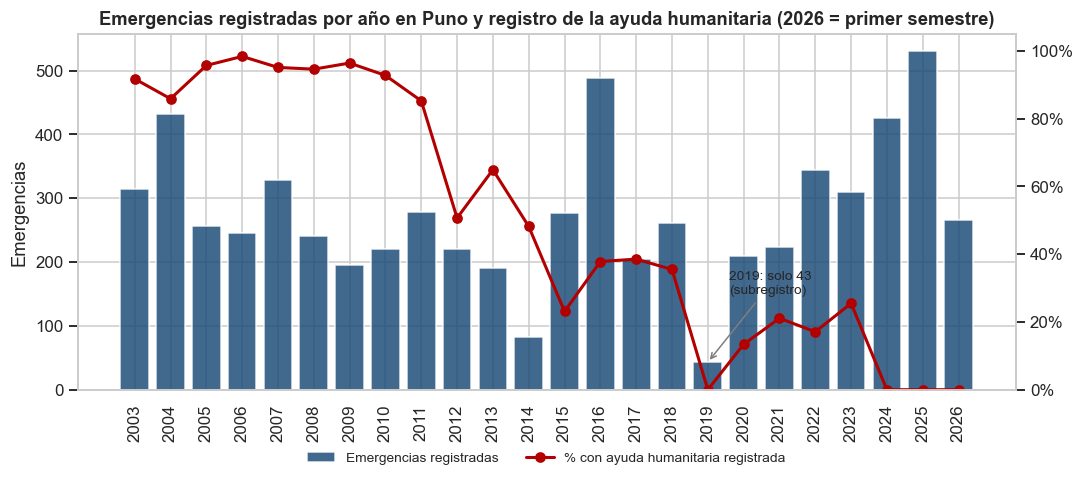

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(calidad.index, calidad["emergencias"], color=AZUL, alpha=.85, label="Emergencias registradas")
ax.set_ylabel("Emergencias"); ax.set_xlabel("")
ax.set_xticks(calidad.index); ax.set_xticklabels(calidad.index, rotation=90)
ax2 = ax.twinx()
ax2.plot(calidad.index, calidad["pct_con_ayuda"], color=ROJO, marker="o", lw=2, label="% con ayuda humanitaria registrada")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax2.set_ylim(0, 1.05); ax2.grid(False)
ax.annotate("2019: solo 43\n(subregistro)", xy=(2019, calidad.loc[2019, "emergencias"]), xytext=(2019.6, 150),
            arrowprops=dict(arrowstyle="->", color=GRIS), fontsize=9)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9, frameon=False)
ax.set_title("Emergencias registradas por año en Puno y registro de la ayuda humanitaria (2026 = primer semestre)")
guardar(fig, "fig01_eventos_por_anio")

**Lo que se ve en la calidad de los datos**

* Las fechas quedaron limpias: con la regla de dos formatos ninguna fecha falla y todas coinciden con el año y el mes registrados. Tampoco hay códigos SINPAD repetidos.
* **2019 tiene solo 43 emergencias** y 2014 solo 83, frente a un promedio de 248 por año entre 2003 y 2021. No fueron años tranquilos: fue un problema de registro, y conviene no leer esos años como una baja del riesgo.
* El registro de la **ayuda humanitaria se fue perdiendo**: pasa de más del 90 % de las emergencias con ayuda anotada (2003-2011) a cero en 2019 y en 2024-2026. Por eso la ayuda entregada **no puede usarse como variable objetivo** ni para medir la respuesta reciente.
* La proporción de emergencias sin ninguna persona impactada sube mucho entre 2014 y 2019 (hasta 57 % en 2017): en esos años se registraron más eventos sin evaluación de daños.
* Desde 2022 el registro crece (403 emergencias por año en promedio en 2022-2025). Una parte puede ser más eventos y otra parte, mejor registro; los datos no permiten separar las dos cosas.

## 2.2 ¿Cuántas personas afecta una emergencia?

In [8]:
desc = puno[["PERSONAS", "DAMNIFICADOS", "AFECTADOS", "VIV_DESTRUIDAS", "VIV_AFECTADAS",
             "HA_CULT_AFECT", "CAMELIDO_PERD", "AYUDA_PESO"]].describe(percentiles=[.5, .75, .9, .99]).T
print(f"Emergencias con 0 personas impactadas: {(puno.PERSONAS == 0).mean():.1%}")
print(f"Emergencias de alto impacto (≥ {UMBRAL} personas): {puno.ALTO.sum():,} ({puno.ALTO.mean():.1%})")
desc[["mean", "50%", "75%", "90%", "99%", "max"]]

Emergencias con 0 personas impactadas: 22.5%
Emergencias de alto impacto (≥ 100 personas): 1,876 (28.5%)


,mean,50%,75%,90%,99%,max
PERSONAS,418.253,9.000,170.000,"1,149.200","5,701.240","54,590.000"
DAMNIFICADOS,17.616,0.000,4.000,20.000,421.200,"2,400.000"
AFECTADOS,400.562,2.000,136.000,"1,084.400","5,415.240","54,590.000"
VIV_DESTRUIDAS,2.747,0.000,1.000,4.000,59.220,500.000
VIV_AFECTADAS,15.453,0.000,1.000,14.000,377.480,"3,495.000"
HA_CULT_AFECT,96.539,0.000,0.000,37.500,"2,115.172","21,506.333"
CAMELIDO_PERD,118.046,0.000,0.000,0.000,"2,485.240","81,470.000"
AYUDA_PESO,852.275,0.000,194.940,"1,642.056","11,824.451","696,660.000"


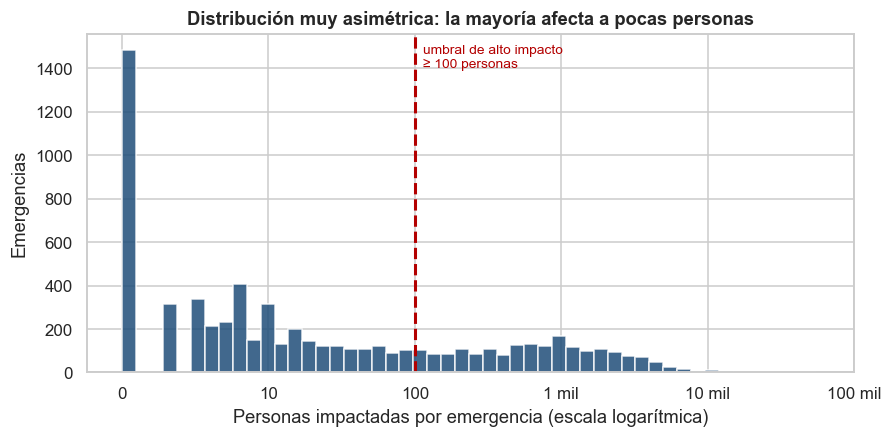

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(np.log10(puno["PERSONAS"] + 1), bins=50, color=AZUL, alpha=.85)
ax.axvline(np.log10(UMBRAL + 1), color=ROJO, ls="--", lw=2)
ax.text(np.log10(UMBRAL + 1) + .05, ax.get_ylim()[1] * .9, f"umbral de alto impacto\n≥ {UMBRAL} personas", color=ROJO, fontsize=9)
ax.set_xticks(range(0, 6)); ax.set_xticklabels(["0", "10", "100", "1 mil", "10 mil", "100 mil"])
ax.set_xlabel("Personas impactadas por emergencia (escala logarítmica)"); ax.set_ylabel("Emergencias")
ax.set_title("Distribución muy asimétrica: la mayoría afecta a pocas personas")
guardar(fig, "fig02_distribucion_personas")

## 2.3 Peligros: frecuencia frente a impacto

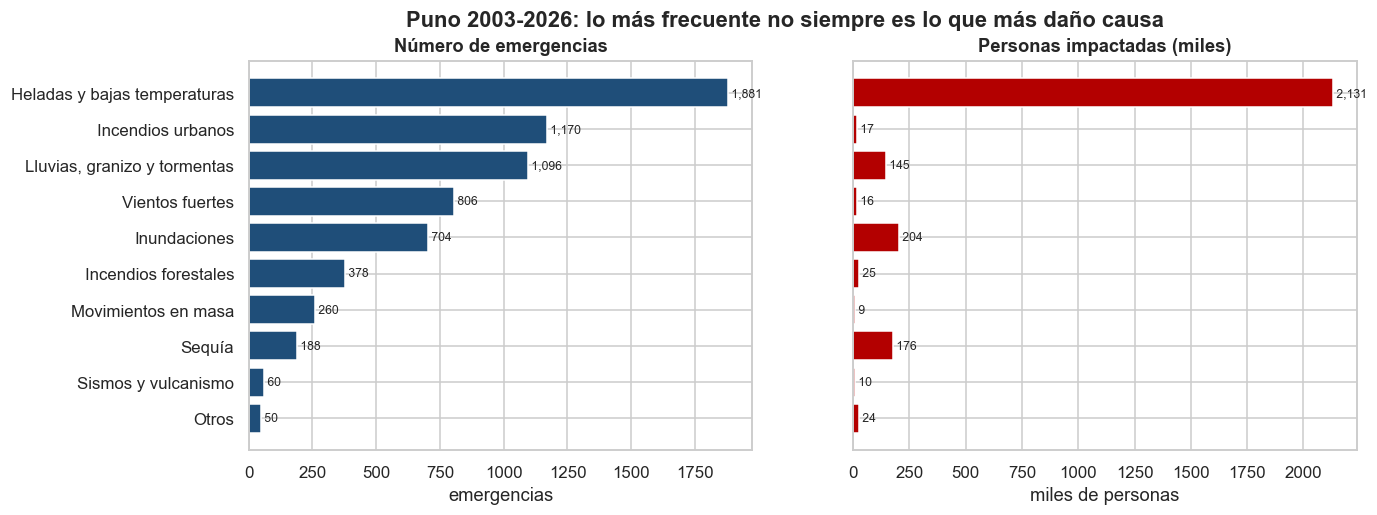

,emergencias,personas,damnificados,viv_destruidas,camelidos_perdidos,pct_alto,mediana_personas
GRUPO,,,,,,,
Heladas y bajas temperaturas,1881,"2,131,413","24,691","1,703","594,811",66%,500
Incendios urbanos,1170,"16,604","10,727","2,227",0,2%,6
"Lluvias, granizo y tormentas",1096,"145,285","24,393","4,118","13,340",20%,6
Vientos fuertes,806,"15,661","4,889","1,004",5,4%,5
Inundaciones,704,"204,426","42,059","6,339","12,947",33%,26
Incendios forestales,378,"25,122","3,658",759,62,6%,3
Movimientos en masa,260,"9,188","3,594",726,9,8%,3
Sequía,188,"175,550",28,14,"153,567",32%,0
Sismos y vulcanismo,60,"10,008","2,103",492,367,25%,1


In [10]:
por_grupo = puno.groupby("GRUPO").agg(emergencias=("COD", "size"), personas=("PERSONAS", "sum"),
                                      damnificados=("DAMNIFICADOS", "sum"), viv_destruidas=("VIV_DESTRUIDAS", "sum"),
                                      camelidos_perdidos=("CAMELIDO_PERD", "sum"), pct_alto=("ALTO", "mean"),
                                      mediana_personas=("PERSONAS", "median")).sort_values("emergencias", ascending=False)
por_grupo.to_csv(RES / "resumen_por_grupo.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
orden = por_grupo.index
axes[0].barh(orden, por_grupo["emergencias"], color=AZUL); axes[0].invert_yaxis()
axes[0].set_title("Número de emergencias"); axes[0].set_xlabel("emergencias")
axes[1].barh(orden, por_grupo["personas"] / 1e3, color=ROJO)
axes[1].set_title("Personas impactadas (miles)"); axes[1].set_xlabel("miles de personas")
for ax, col, div in [(axes[0], "emergencias", 1), (axes[1], "personas", 1e3)]:
    for i, v in enumerate(por_grupo[col] / div):
        ax.text(v, i, f" {v:,.0f}", va="center", fontsize=8)
fig.suptitle("Puno 2003-2026: lo más frecuente no siempre es lo que más daño causa", fontweight="bold")
guardar(fig, "fig03_frecuencia_vs_impacto")
por_grupo.style.format({"personas": "{:,.0f}", "damnificados": "{:,.0f}", "viv_destruidas": "{:,.0f}",
                        "camelidos_perdidos": "{:,.0f}", "pct_alto": "{:.0%}", "mediana_personas": "{:,.0f}"})

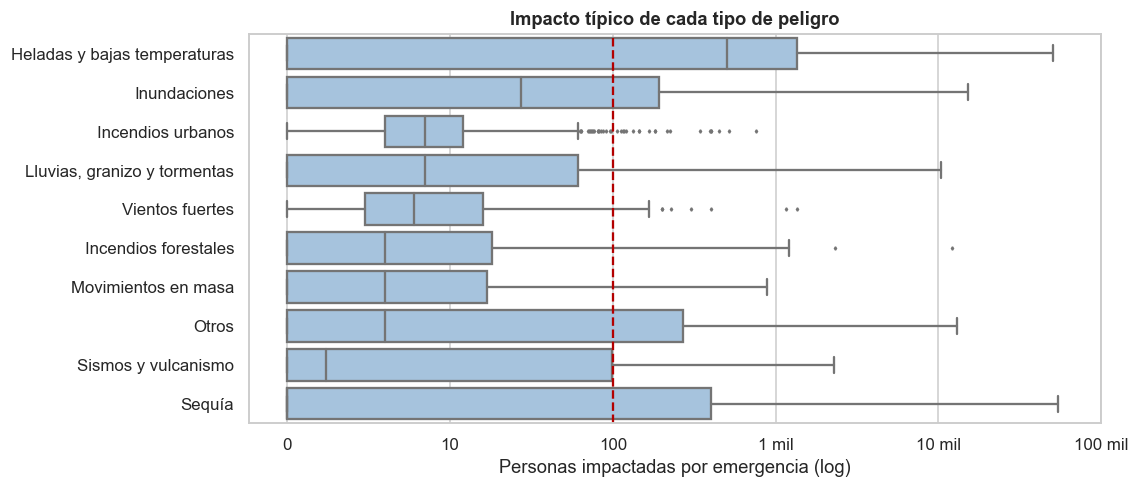

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.6))
orden_med = puno.groupby("GRUPO")["PERSONAS"].median().sort_values(ascending=False).index
sns.boxplot(data=puno, y="GRUPO", x=np.log10(puno["PERSONAS"] + 1), order=orden_med, color="#9dc3e6",
            fliersize=1.5, ax=ax)
ax.axvline(np.log10(UMBRAL + 1), color=ROJO, ls="--")
ax.set_xticks(range(0, 6)); ax.set_xticklabels(["0", "10", "100", "1 mil", "10 mil", "100 mil"])
ax.set_xlabel("Personas impactadas por emergencia (log)"); ax.set_ylabel("")
ax.set_title("Impacto típico de cada tipo de peligro")
guardar(fig, "fig04_impacto_por_peligro")

**Frecuencia frente a impacto**

* Las **heladas y bajas temperaturas** son el 29 % de las emergencias, pero concentran el **77 % de las personas impactadas** y el **76 % de los camélidos perdidos**. El 66 % de ellas supera las 100 personas, y su mediana es de 500 personas por emergencia.
* Los **incendios urbanos** son el segundo peligro más frecuente (1 170 casos), pero casi nunca son de alto impacto (2 %): afectan a una o pocas familias.
* Las **inundaciones** y la **sequía** son menos frecuentes, pero cuando ocurren afectan a muchas personas (un tercio de ellas son de alto impacto). La sequía casi no deja damnificados, pero sí ganado perdido (20 % de los camélidos).
* Hay que leer las cifras como **personas-evento**: la suma acumulada (2,76 millones) cuenta varias veces a la misma familia si fue afectada en varias temporadas, así que no equivale al número de habitantes afectados.

## 2.4 Estacionalidad

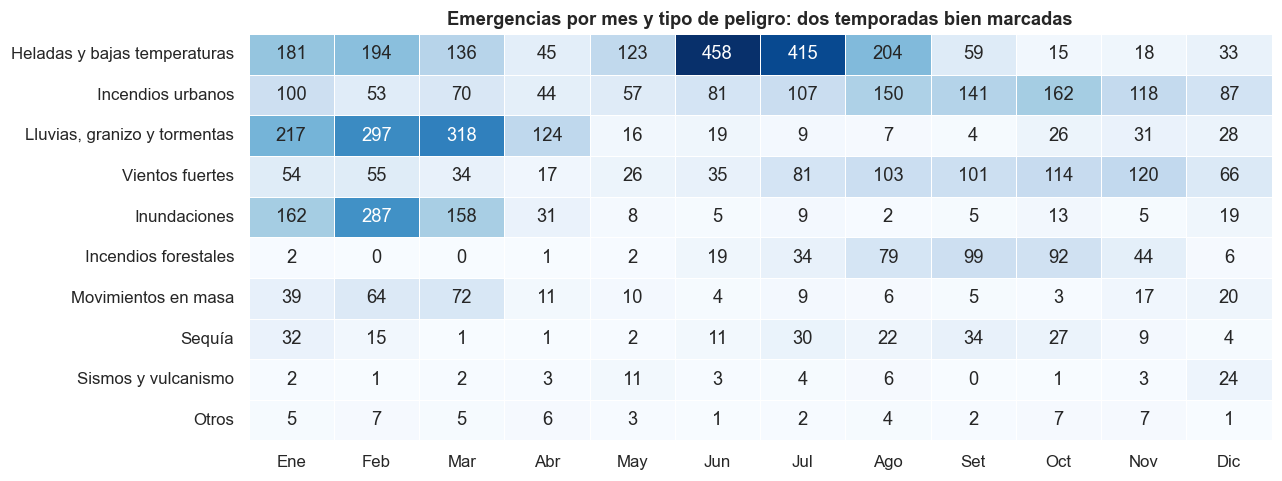

In [12]:
puno["MES_NUM"] = puno["FECHA"].dt.month
tabla_mes = pd.crosstab(puno["GRUPO"], puno["MES_NUM"]).reindex(orden)
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.heatmap(tabla_mes, cmap="Blues", annot=True, fmt="d", cbar=False, linewidths=.4, ax=ax,
            xticklabels=[m[:3].title() for m in MESES])
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Emergencias por mes y tipo de peligro: dos temporadas bien marcadas")
guardar(fig, "fig05_estacionalidad")

**Dos temporadas muy marcadas**

* **Temporada de lluvias (diciembre-marzo):** concentra el 78 % de las emergencias por lluvias, granizo y tormentas y el 89 % de las inundaciones. Febrero es el mes con más emergencias del año (973).
* **Temporada de heladas (mayo-agosto):** concentra el 64 % de las emergencias por bajas temperaturas; solo junio y julio reúnen el 46 %.
* **Fin de la época seca (agosto-octubre):** el 71 % de los incendios forestales ocurre en estos tres meses, junto con los vientos fuertes.
* Abril, mayo y diciembre son los meses más tranquilos. Esto ordena el calendario de preparación: abastecer antes de mayo para las heladas y antes de diciembre para las lluvias.

## 2.5 Distribución territorial

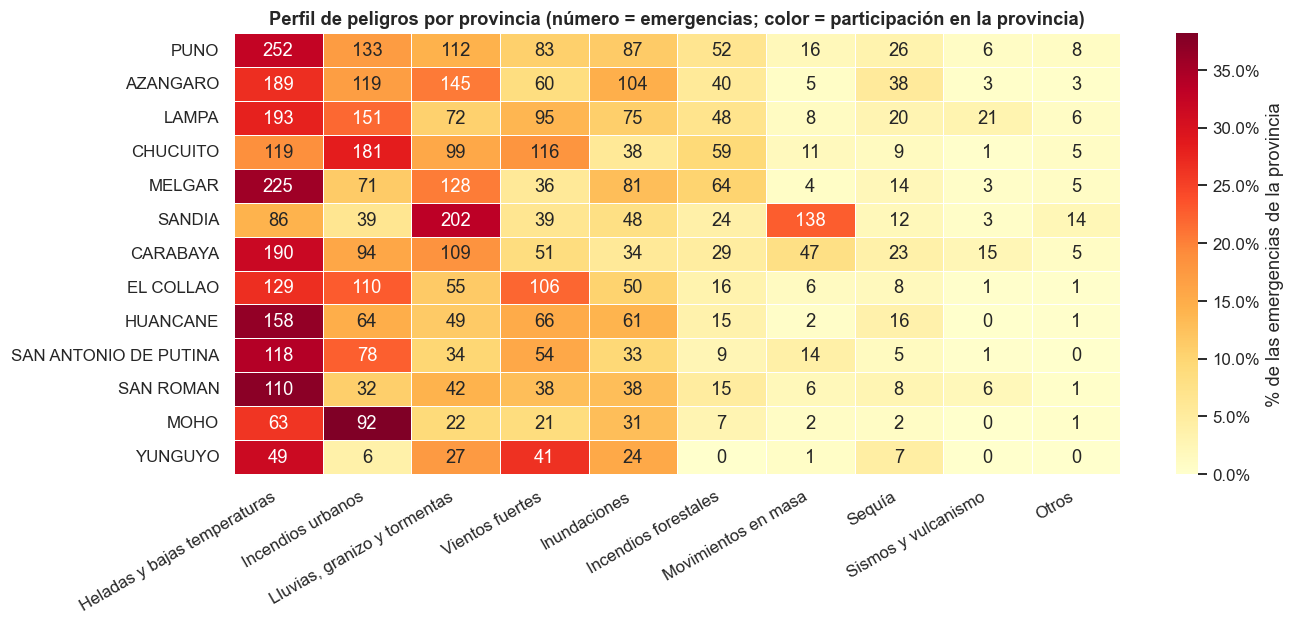

In [13]:
tabla_prov = pd.crosstab(puno["PROV"], puno["GRUPO"])[orden]
tabla_prov = tabla_prov.loc[tabla_prov.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 5.2))
sns.heatmap(tabla_prov.div(tabla_prov.sum(axis=1), axis=0), cmap="YlOrRd", annot=tabla_prov, fmt="d",
            cbar_kws={"label": "% de las emergencias de la provincia", "format": mtick.PercentFormatter(1)},
            linewidths=.4, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_title("Perfil de peligros por provincia (número = emergencias; color = participación en la provincia)")
guardar(fig, "fig06_provincia_peligro")

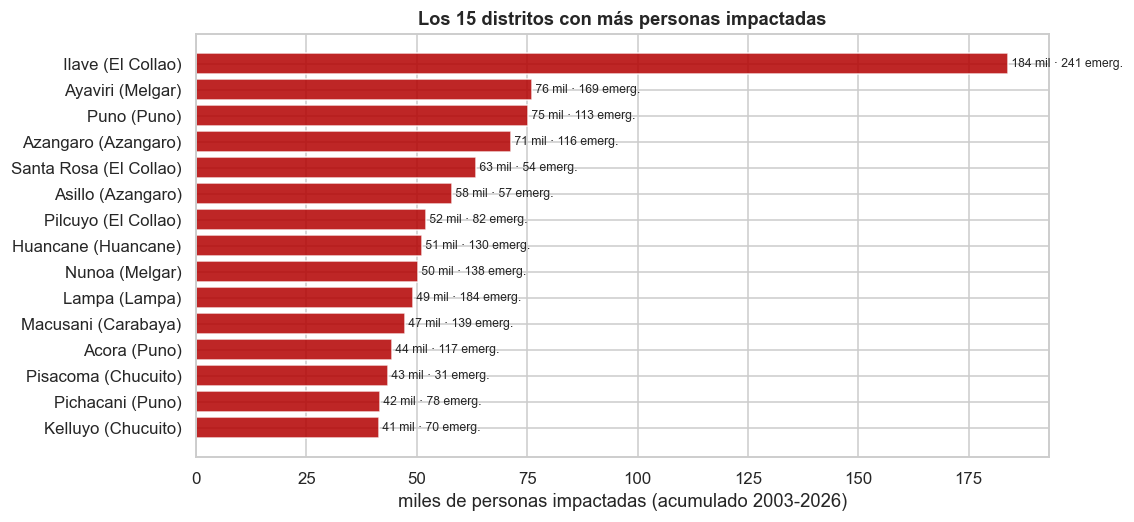

,PROV,DIST,emergencias,personas,pct_alto
0,EL COLLAO,ILAVE,241,183938,0.145
1,MELGAR,AYAVIRI,169,76192,0.272
2,PUNO,PUNO,113,75177,0.186
3,AZANGARO,AZANGARO,116,71387,0.267
4,EL COLLAO,SANTA ROSA,54,63357,0.389
5,AZANGARO,ASILLO,57,58052,0.474
6,EL COLLAO,PILCUYO,82,52069,0.244
7,HUANCANE,HUANCANE,130,51184,0.238
8,MELGAR,NUNOA,138,50364,0.210
9,LAMPA,LAMPA,184,49020,0.207


In [14]:
top_dist = (puno.groupby(["PROV", "DIST"]).agg(emergencias=("COD", "size"), personas=("PERSONAS", "sum"),
                                                pct_alto=("ALTO", "mean"))
            .sort_values("personas", ascending=False).head(15).reset_index())
top_dist["etiqueta"] = top_dist["DIST"].str.title() + " (" + top_dist["PROV"].str.title() + ")"
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_dist["etiqueta"], top_dist["personas"] / 1e3, color=ROJO, alpha=.85); ax.invert_yaxis()
for i, (p, e) in enumerate(zip(top_dist["personas"] / 1e3, top_dist["emergencias"])):
    ax.text(p, i, f" {p:,.0f} mil · {e} emerg.", va="center", fontsize=8)
ax.set_xlabel("miles de personas impactadas (acumulado 2003-2026)")
ax.set_title("Los 15 distritos con más personas impactadas")
guardar(fig, "fig07_top_distritos")
top_dist.drop(columns="etiqueta")

**Distribución territorial**

* Las heladas dominan en casi todas las provincias del altiplano (Puno, Melgar, Carabaya, Huancané, San Román).
* **Sandía** es distinta: es la provincia de selva alta y el 56 % de sus emergencias son lluvias intensas y movimientos en masa (huaicos, deslizamientos). **Moho** y **Chucuito** tienen una proporción alta de incendios urbanos, y **El Collao** y **Yunguyo**, de vientos fuertes.
* Por personas impactadas acumuladas destacan Azángaro, Puno y El Collao. **Ilave** (El Collao) es el distrito con más personas impactadas (184 mil personas-evento en 241 emergencias). Las dos emergencias más grandes de la serie ocurrieron allí en enero de 2016 (sequía y bajas temperaturas, con más de 50 mil personas cada una).
* Los 15 distritos de la figura reúnen el 34 % de todas las personas impactadas: el riesgo está concentrado.

## 2.6 Tendencias y daños productivos

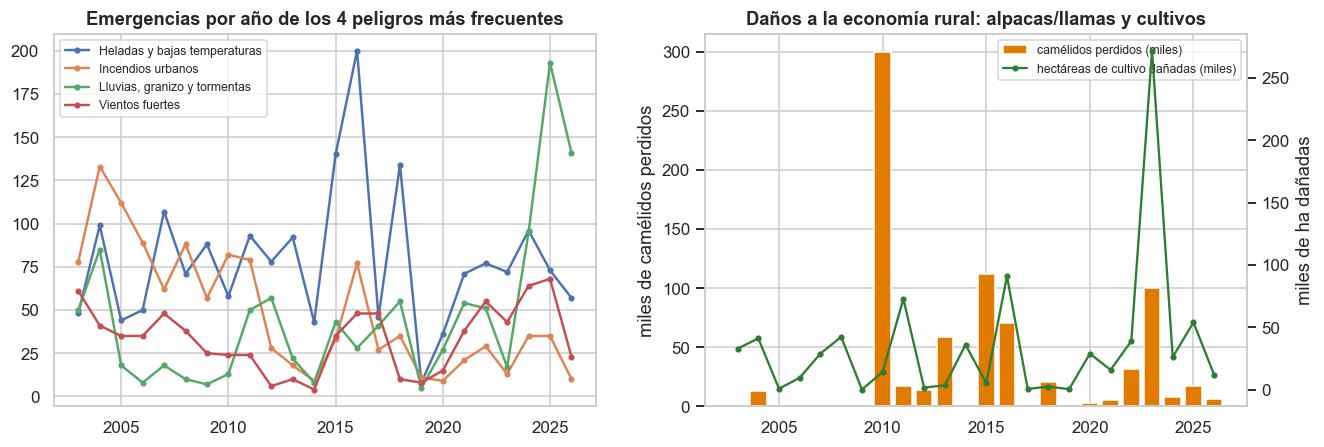

In [15]:
top4 = list(orden[:4])
serie = puno[puno.GRUPO.isin(top4)].groupby(["ANIO", "GRUPO"]).size().unstack(fill_value=0)
anual = puno.groupby("ANIO")[["CAMELIDO_PERD", "HA_CULT_DESTR", "HA_CULT_AFECT"]].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
serie.plot(ax=axes[0], marker="o", ms=3, lw=1.6)
axes[0].set_title("Emergencias por año de los 4 peligros más frecuentes"); axes[0].set_xlabel(""); axes[0].legend(fontsize=8)
axes[1].bar(anual.index, anual["CAMELIDO_PERD"] / 1e3, color=NARANJA, label="camélidos perdidos (miles)")
axes[1].set_ylabel("miles de camélidos perdidos")
ax2 = axes[1].twinx(); ax2.grid(False)
ax2.plot(anual.index, (anual["HA_CULT_DESTR"] + anual["HA_CULT_AFECT"]) / 1e3, color=VERDE, marker="o", ms=3,
         label="hectáreas de cultivo dañadas (miles)")
ax2.set_ylabel("miles de ha dañadas")
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
axes[1].set_title("Daños a la economía rural: alpacas/llamas y cultivos")
guardar(fig, "fig08_tendencias_y_danos")

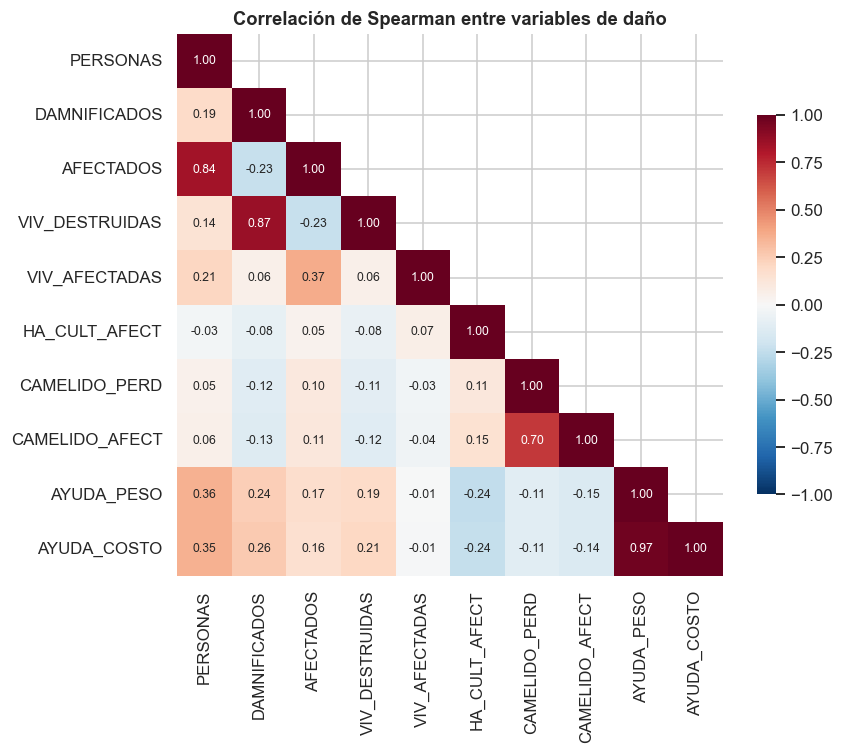

In [16]:
imp = ["PERSONAS", "DAMNIFICADOS", "AFECTADOS", "VIV_DESTRUIDAS", "VIV_AFECTADAS", "HA_CULT_AFECT",
       "CAMELIDO_PERD", "CAMELIDO_AFECT", "AYUDA_PESO", "AYUDA_COSTO"]
corr = puno[imp].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.4))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
            mask=np.triu(np.ones_like(corr, dtype=bool), 1), ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlación de Spearman entre variables de daño")
guardar(fig, "fig09_correlaciones")

**Tendencias y daños productivos**

* Las heladas son la amenaza más constante a lo largo de toda la serie. Las lluvias e inundaciones tienen picos en años concretos.
* Las pérdidas de **camélidos** (alpacas y llamas) se concentran en pocos años: 2010 (unos 300 mil) y 2015 (112 mil), registradas como bajas temperaturas, y 2023 (100 mil), registradas como sequía. Son golpes muy fuertes para la economía alpaquera.
* 2023 es también el año con más hectáreas de cultivo dañadas (unas 272 mil, el 93 % por sequía), muy por encima del resto: la sequía no deja damnificados, pero arrasa con la producción agropecuaria.
* Las correlaciones de Spearman muestran que **afectados** y **damnificados** miden cosas distintas (incluso con signo opuesto): los damnificados van con las viviendas destruidas (0,79) y los afectados, con el total de personas (0,84). La ayuda entregada se relaciona poco con los daños (0,36 con las personas), otra señal de que su registro es irregular.

---
# 3. Selección de modelos

## 3.1 Planteamiento del problema

**Pregunta de negocio.** Cuando un distrito reporta una emergencia, la Oficina de Defensa Civil todavía no sabe
cuántas personas resultarán afectadas: eso se conoce días después, con el EDAN. Si en ese momento se pudiera
estimar la probabilidad de que la emergencia sea de **alto impacto (≥ 100 personas impactadas)**, se podría
priorizar el envío de equipos evaluadores y de bienes de ayuda.

**Tarea:** clasificación binaria. **Objetivo:** `ALTO`.

**Variables predictoras.** Solo se usa información disponible *cuando se reporta la emergencia*, para no hacer
trampa con los daños (que son justamente lo que se quiere anticipar):

| Grupo | Variables |
|---|---|
| Qué pasó | familia de peligro, tipo de peligro (natural/inducido) |
| Dónde | provincia, región natural |
| Cuándo | mes (codificado como seno y coseno), año |
| Historia del lugar (solo con emergencias **anteriores** a la fecha) | número de emergencias previas en el distrito, tasa previa de alto impacto en el distrito, promedio previo de personas impactadas (log), días desde la última emergencia del distrito, emergencias previas y tasa de alto impacto de ese mismo peligro en la provincia, emergencias en la provincia en los 30 días anteriores |

Las tasas históricas se suavizan hacia la tasa general del periodo de entrenamiento para que un distrito con
una sola emergencia previa no reciba un 0 % o un 100 %.

**Partición temporal.** Entrenamiento: 2003-2021. Prueba: 2022-2026 (datos que el modelo nunca ve). Dentro del
entrenamiento, la validación cruzada usa `TimeSeriesSplit` con 5 bloques: siempre se entrena con el pasado y se
valida con el futuro, como ocurriría en la práctica.

In [17]:
df = puno.copy()
df["MES_SIN"] = np.sin(2 * np.pi * df["MES_NUM"] / 12)
df["MES_COS"] = np.cos(2 * np.pi * df["MES_NUM"] / 12)
df["LOGP"] = np.log1p(df["PERSONAS"])
CORTE = 2022
PRIOR = df.loc[df.ANIO < CORTE, "ALTO"].mean()
PRIOR_LOGP = df.loc[df.ANIO < CORTE, "LOGP"].mean()

def historial(d, clave, pref, m=10):
    """Variables con emergencias estrictamente anteriores a la fecha (sin fuga de información)."""
    g = (d.groupby(clave + ["FECHA"]).agg(n=("ALTO", "size"), a=("ALTO", "sum"), s=("LOGP", "sum"))
           .reset_index().sort_values(clave + ["FECHA"]))
    grp = g.groupby(clave)
    n_prev = grp["n"].cumsum() - g["n"]
    g[f"{pref}_N_PREV"] = n_prev
    g[f"{pref}_TASA_PREV"] = (grp["a"].cumsum() - g["a"] + m * PRIOR) / (n_prev + m)
    g[f"{pref}_LOGP_PREV"] = (grp["s"].cumsum() - g["s"] + m * PRIOR_LOGP) / (n_prev + m)
    g[f"{pref}_DIAS_ULT"] = grp["FECHA"].diff().dt.days.fillna(3650).clip(upper=3650)
    cols = [f"{pref}_N_PREV", f"{pref}_TASA_PREV", f"{pref}_LOGP_PREV", f"{pref}_DIAS_ULT"]
    return d.merge(g[clave + ["FECHA"] + cols], on=clave + ["FECHA"], how="left")

df = historial(df, ["UBIGEO"], "DIST")
df = historial(df, ["PROV", "GRUPO"], "PG")

ventanas = []
for prov, g in df.groupby("PROV"):
    s = g.groupby("FECHA").size().asfreq("D", fill_value=0)
    r = s.rolling(30, min_periods=1).sum().shift(1).fillna(0)
    ventanas.append(pd.DataFrame({"PROV": prov, "FECHA": r.index, "PROV_30D": r.values}))
df = df.merge(pd.concat(ventanas), on=["PROV", "FECHA"], how="left")
df = df.sort_values(["FECHA", "COD"]).reset_index(drop=True)

CAT = ["GRUPO", "TIPO", "REGION", "PROV"]
NUM = ["MES_SIN", "MES_COS", "ANIO", "DIST_N_PREV", "DIST_TASA_PREV", "DIST_LOGP_PREV", "DIST_DIAS_ULT",
       "PG_N_PREV", "PG_TASA_PREV", "PROV_30D"]
X, y = df[CAT + NUM], df["ALTO"]
es_train = df["ANIO"] < CORTE
Xtr, ytr, Xte, yte = X[es_train], y[es_train], X[~es_train], y[~es_train]
print(f"Entrenamiento 2003-{CORTE - 1}: {len(Xtr):,} emergencias, {ytr.mean():.1%} de alto impacto")
print(f"Prueba {CORTE}-2026:        {len(Xte):,} emergencias, {yte.mean():.1%} de alto impacto")
df[CAT + NUM + ["ALTO"]].head()

Entrenamiento 2003-2021: 4,715 emergencias, 31.2% de alto impacto
Prueba 2022-2026:        1,878 emergencias, 21.6% de alto impacto


,GRUPO,TIPO,REGION,PROV,MES_SIN,MES_COS,ANIO,DIST_N_PREV,DIST_TASA_PREV,DIST_LOGP_PREV,DIST_DIAS_ULT,PG_N_PREV,PG_TASA_PREV,PROV_30D,ALTO
0,"Lluvias, granizo y tormentas",ORIGEN NATURAL,SIERRA,CHUCUITO,0.500,0.866,2003,0,0.312,3.193,"3,650.000",0,0.312,0.000,0
1,Heladas y bajas temperaturas,ORIGEN NATURAL,SIERRA,AZANGARO,0.500,0.866,2003,0,0.312,3.193,"3,650.000",0,0.312,0.000,1
2,"Lluvias, granizo y tormentas",ORIGEN NATURAL,SIERRA,SANDIA,0.500,0.866,2003,0,0.312,3.193,"3,650.000",0,0.312,0.000,1
3,Vientos fuertes,ORIGEN NATURAL,SIERRA,LAMPA,0.500,0.866,2003,0,0.312,3.193,"3,650.000",0,0.312,0.000,1
4,Inundaciones,ORIGEN NATURAL,SIERRA,AZANGARO,0.500,0.866,2003,0,0.312,3.193,"3,650.000",0,0.312,1.000,1


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, brier_score_loss, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def preprocesador(escalar):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
                              ("num", StandardScaler() if escalar else "passthrough", NUM)])

SPW = (1 - ytr.mean()) / ytr.mean()
MODELOS = {
    "Línea base (azar estratificado)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Regresión logística": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED),
    "k vecinos (k=25)": KNeighborsClassifier(n_neighbors=25),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                            n_jobs=2, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=SPW, eval_metric="logloss", random_state=SEED, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, is_unbalance=True, random_state=SEED, verbose=-1, n_jobs=-1),
}
ESCALAR = {"Regresión logística", "k vecinos (k=25)"}
CV = TimeSeriesSplit(n_splits=5)
METRICAS = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "F1": "f1",
            "Exactitud balanceada": "balanced_accuracy", "Brier": "neg_brier_score"}

filas, por_fold = [], {}
for nombre, modelo in MODELOS.items():
    pipe = Pipeline([("prep", preprocesador(nombre in ESCALAR)), ("modelo", modelo)])
    t0 = time.time()
    r = cross_validate(pipe, Xtr, ytr, cv=CV, scoring=METRICAS)
    fila = {"Modelo": nombre}
    for k in METRICAS:
        v = r[f"test_{k}"] * (-1 if k == "Brier" else 1)
        fila[k] = v.mean(); fila[f"{k} (de)"] = v.std()
    fila["Tiempo (s)"] = time.time() - t0
    filas.append(fila); por_fold[nombre] = r["test_ROC-AUC"]

comparacion = pd.DataFrame(filas).set_index("Modelo").sort_values("ROC-AUC", ascending=False)
comparacion.to_csv(RES / "seleccion_modelos_cv.csv")
comparacion[["ROC-AUC", "ROC-AUC (de)", "PR-AUC", "F1", "Exactitud balanceada", "Brier", "Tiempo (s)"]]

,ROC-AUC,ROC-AUC (de),PR-AUC,F1,Exactitud balanceada,Brier,Tiempo (s)
Modelo,,,,,,,
Random Forest,0.882,0.043,0.772,0.742,0.809,0.122,9.525
k vecinos (k=25),0.879,0.036,0.760,0.714,0.791,0.125,1.178
Regresión logística,0.875,0.041,0.778,0.679,0.780,0.162,0.320
HistGradientBoosting,0.868,0.041,0.758,0.696,0.777,0.128,6.766
XGBoost,0.867,0.037,0.759,0.711,0.785,0.126,2.176
LightGBM,0.864,0.040,0.760,0.711,0.783,0.128,5.018
Árbol de decisión,0.771,0.114,0.635,0.625,0.735,0.173,0.226
Línea base (azar estratificado),0.507,0.016,0.316,0.312,0.507,0.427,0.122


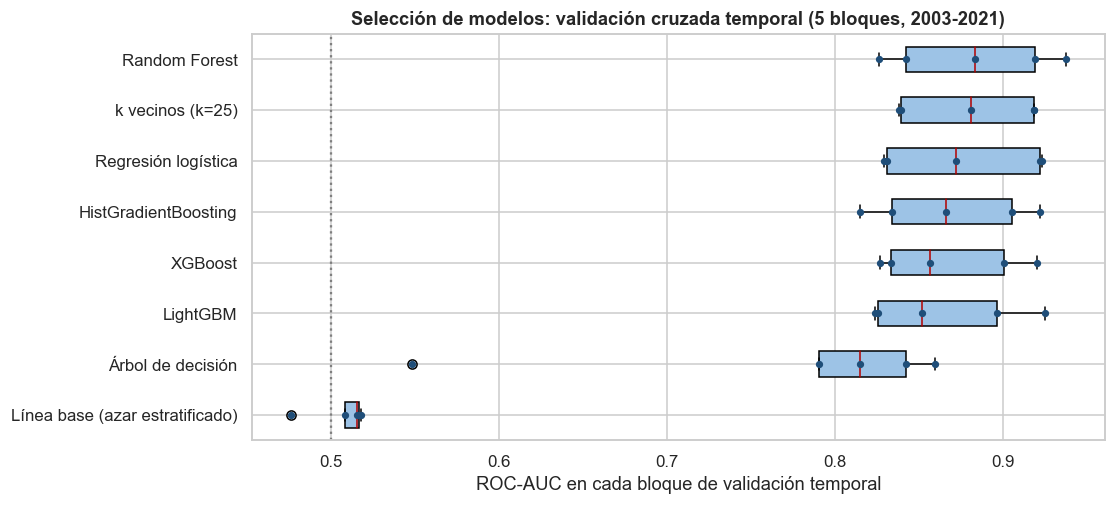

Mejor modelo en validación cruzada: Random Forest
Familia que se optimiza en el paso 4: Random Forest


In [19]:
orden_m = comparacion.index[::-1]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.boxplot([por_fold[m] for m in orden_m], vert=False, labels=orden_m, patch_artist=True,
           boxprops=dict(facecolor="#9dc3e6"), medianprops=dict(color=ROJO))
for i, m in enumerate(orden_m, start=1):
    ax.scatter(por_fold[m], np.full(5, i), color=AZUL, s=14, zorder=3)
ax.axvline(0.5, color=GRIS, ls=":"); ax.set_xlabel("ROC-AUC en cada bloque de validación temporal")
ax.set_title("Selección de modelos: validación cruzada temporal (5 bloques, 2003-2021)")
guardar(fig, "fig10_seleccion_modelos")

ESPACIOS_DISPONIBLES = ["LightGBM", "XGBoost", "Random Forest", "HistGradientBoosting"]
candidatos = [m for m in comparacion.index if m in ESPACIOS_DISPONIBLES]
FAMILIA = candidatos[0]
print("Mejor modelo en validación cruzada:", comparacion.index[0])
print("Familia que se optimiza en el paso 4:", FAMILIA)

**Resultado de la selección**

* Todos los modelos superan con amplitud a la línea base (ROC-AUC 0,51): la información disponible al momento del reporte sí permite anticipar el impacto.
* **Random Forest** queda primero (ROC-AUC 0,882 y la mejor F1, 0,742), seguido muy de cerca por k vecinos (0,879) y la regresión logística (0,875). Los métodos de *boosting* (HistGradientBoosting, XGBoost, LightGBM) quedan entre 0,864 y 0,868 con sus valores por defecto.
* Las diferencias entre los seis primeros son pequeñas comparadas con la variación entre bloques (desviación de unos 0,04): el bloque temporal en que se valida importa más que el algoritmo. El árbol de decisión simple es claramente peor (0,771) y el más inestable.
* Se elige Random Forest para el paso 4 porque tiene la mejor ROC-AUC, la mejor F1 y la mejor calibración (Brier 0,122).

---
# 4. Optimización de hiperparámetros

Se toma la familia ganadora del paso 3 y se buscan sus mejores hiperparámetros con **cuatro estrategias**, todas
con el **mismo presupuesto (40 evaluaciones)**, la misma métrica (ROC-AUC promedio en los 5 bloques temporales) y
el mismo espacio de búsqueda:

| Estrategia | Librería | Cómo propone el siguiente punto |
|---|---|---|
| Búsqueda aleatoria | Optuna `RandomSampler` | Al azar: es la base de comparación |
| TPE + poda | **Optuna** `TPESampler` + `MedianPruner` | Modela qué zonas del espacio dan buenos resultados y abandona a mitad de camino las pruebas que van peor que la mediana |
| Proceso gaussiano | **scikit-optimize** `gp_minimize` | Optimización bayesiana clásica: ajusta un GP a los resultados y elige el punto con mayor mejora esperada |
| TPE clásico | **Hyperopt** `fmin(tpe.suggest)` | El algoritmo TPE original (Bergstra et al., 2011) |

**Ray Tune** y **BoTorch/Ax**, también recomendados en clase, se dejan fuera de la ejecución: Ray Tune está pensado
para repartir pruebas entre muchos procesadores o máquinas (y en realidad puede usar por dentro los mismos
algoritmos de Optuna o Hyperopt), y BoTorch/Ax requiere PyTorch y brilla con espacios continuos y evaluaciones muy
caras. Con unas 4 700 filas y un entrenamiento de segundos no añadirían nada a la comparación.

In [20]:
ESPACIOS = {
    "LightGBM": {"n_estimators": ("int", 100, 1000, True), "learning_rate": ("float", 0.005, 0.3, True),
                 "num_leaves": ("int", 4, 128, True), "min_child_samples": ("int", 5, 150, True),
                 "subsample": ("float", 0.5, 1.0, False), "colsample_bytree": ("float", 0.3, 1.0, False),
                 "reg_lambda": ("float", 1e-3, 30.0, True)},
    "XGBoost": {"n_estimators": ("int", 100, 1000, True), "learning_rate": ("float", 0.005, 0.3, True),
                "max_depth": ("int", 2, 10, False), "min_child_weight": ("float", 0.5, 30.0, True),
                "subsample": ("float", 0.5, 1.0, False), "colsample_bytree": ("float", 0.3, 1.0, False),
                "reg_lambda": ("float", 1e-3, 30.0, True)},
    "Random Forest": {"n_estimators": ("int", 100, 300, True), "max_depth": ("int", 3, 30, False),
                      "min_samples_leaf": ("int", 1, 50, True), "max_features": ("float", 0.1, 1.0, False)},
    "HistGradientBoosting": {"learning_rate": ("float", 0.01, 0.3, True), "max_iter": ("int", 100, 800, True),
                             "max_leaf_nodes": ("int", 4, 128, True), "min_samples_leaf": ("int", 5, 150, True),
                             "l2_regularization": ("float", 1e-3, 30.0, True)},
}
ESPACIO = ESPACIOS[FAMILIA]

def construir(params, familia=FAMILIA):
    p = dict(params)
    if familia == "LightGBM":
        m = LGBMClassifier(subsample_freq=1, is_unbalance=True, random_state=SEED, verbose=-1, n_jobs=-1, **p)
    elif familia == "XGBoost":
        m = XGBClassifier(scale_pos_weight=SPW, eval_metric="logloss", random_state=SEED, n_jobs=-1, **p)
    elif familia == "Random Forest":
        m = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=2, random_state=SEED, **p)
    else:
        m = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED, **p)
    return Pipeline([("prep", preprocesador(False)), ("modelo", m)])

FOLDS = list(CV.split(Xtr))
def evaluar(params, informar=None):
    """ROC-AUC promedio en los bloques temporales. `informar(k, valor)` permite la poda de Optuna."""
    s = []
    for k, (itr, iva) in enumerate(FOLDS):
        mdl = construir(params).fit(Xtr.iloc[itr], ytr.iloc[itr])
        s.append(roc_auc_score(ytr.iloc[iva], mdl.predict_proba(Xtr.iloc[iva])[:, 1]))
        if informar:
            informar(k, float(np.mean(s)))
    return float(np.mean(s))

def limpiar(params):
    return {k: (int(round(v)) if ESPACIO[k][0] == "int" else float(v)) for k, v in params.items()}

N_EVAL = 40
HISTORIAL = {}
import joblib
def cache(nombre):
    """Ruta donde se guarda cada optimizador al terminar (si la ejecución se corta, no se repite)."""
    return RES / f"cache_{nombre.split()[0].lower()}.joblib"
print("Familia:", FAMILIA); pd.DataFrame(ESPACIO, index=["tipo", "mín", "máx", "escala log"]).T

Familia: Random Forest


,tipo,mín,máx,escala log
n_estimators,int,100,300,True
max_depth,int,3,30,False
min_samples_leaf,int,1,50,True
max_features,float,0.100,1.000,False


In [21]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def sugerir(trial):
    return {k: (trial.suggest_int(k, lo, hi, log=lg) if t == "int" else trial.suggest_float(k, lo, hi, log=lg))
            for k, (t, lo, hi, lg) in ESPACIO.items()}

def correr_optuna(nombre, sampler, pruner=None):
    reg, t0 = [], time.time()
    def objetivo(trial):
        params = sugerir(trial)
        def informar(k, v):
            trial.report(v, k)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return evaluar(params, informar if pruner else None)
    def registrar(study, trial):
        val = trial.value if trial.state == optuna.trial.TrialState.COMPLETE else np.nan
        reg.append({"eval": trial.number + 1, "valor": val, "params": trial.params, "seg": time.time() - t0,
                    "podada": trial.state == optuna.trial.TrialState.PRUNED})
    study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner or optuna.pruners.NopPruner())
    study.optimize(objetivo, n_trials=N_EVAL, callbacks=[registrar])
    HISTORIAL[nombre] = pd.DataFrame(reg)
    return study

def con_cache(nombre, fn):
    if cache(nombre).exists():
        est, HISTORIAL[nombre] = joblib.load(cache(nombre))
    else:
        est = fn(); joblib.dump((est, HISTORIAL[nombre]), cache(nombre))
    print(f"{nombre:<20}{HISTORIAL[nombre].valor.max():.4f}  ({HISTORIAL[nombre].seg.max():.0f} s)")
    return est

estudio_azar = con_cache("Búsqueda aleatoria", lambda: correr_optuna("Búsqueda aleatoria", optuna.samplers.RandomSampler(seed=SEED)))
estudio_tpe = con_cache("Optuna TPE + poda", lambda: correr_optuna(
    "Optuna TPE + poda", optuna.samplers.TPESampler(seed=SEED, multivariate=True),
    optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1)))

Búsqueda aleatoria  0.8904  (338 s)
Optuna TPE + poda   0.8911  (236 s)


In [22]:
from skopt import gp_minimize
from skopt.space import Integer, Real

claves = list(ESPACIO)
dims = [(Integer if t == "int" else Real)(lo, hi, prior="log-uniform" if lg else "uniform", name=k)
        for k, (t, lo, hi, lg) in ESPACIO.items()]
reg, t0 = [], time.time()
def f_skopt(x):
    p = limpiar(dict(zip(claves, x)))
    v = evaluar(p)
    reg.append({"eval": len(reg) + 1, "valor": v, "params": p, "seg": time.time() - t0, "podada": False})
    return -v
def _skopt():
    gp_minimize(f_skopt, dims, n_calls=N_EVAL, n_initial_points=10, random_state=SEED)
    HISTORIAL["scikit-optimize (GP)"] = pd.DataFrame(reg)
con_cache("scikit-optimize (GP)", _skopt)

scikit-optimize (GP)0.8907  (296 s)


In [23]:
from hyperopt import fmin, tpe, hp, Trials

espacio_hp = {}
for k, (t, lo, hi, lg) in ESPACIO.items():
    if t == "int":
        espacio_hp[k] = hp.qloguniform(k, np.log(lo), np.log(hi), 1) if lg else hp.quniform(k, lo, hi, 1)
    else:
        espacio_hp[k] = hp.loguniform(k, np.log(lo), np.log(hi)) if lg else hp.uniform(k, lo, hi)

reg, t0 = [], time.time()
def f_hyperopt(p):
    p = limpiar(p)
    p = {k: (min(max(v, ESPACIO[k][1]), ESPACIO[k][2]) if ESPACIO[k][0] == "int" else v) for k, v in p.items()}
    v = evaluar(p)
    reg.append({"eval": len(reg) + 1, "valor": v, "params": p, "seg": time.time() - t0, "podada": False})
    return -v
def _hyperopt():
    fmin(f_hyperopt, espacio_hp, algo=tpe.suggest, max_evals=N_EVAL, trials=Trials(),
         rstate=np.random.default_rng(SEED), show_progressbar=False)
    HISTORIAL["Hyperopt (TPE)"] = pd.DataFrame(reg)
con_cache("Hyperopt (TPE)", _hyperopt)

Hyperopt (TPE)      0.8906  (366 s)


In [24]:
DEFAULT_AUC = comparacion.loc[FAMILIA, "ROC-AUC"]
filas = []
for nombre, h in HISTORIAL.items():
    i = h["valor"].idxmax()
    filas.append({"Estrategia": nombre, "Mejor ROC-AUC (CV)": h.loc[i, "valor"],
                  "Mejora vs. por defecto": h.loc[i, "valor"] - DEFAULT_AUC,
                  "Evaluación en que lo alcanzó": int(h.loc[i, "eval"]),
                  "Pruebas podadas": int(h["podada"].sum()), "Tiempo total (s)": h["seg"].max()})
tabla_opt = pd.DataFrame(filas).set_index("Estrategia").sort_values("Mejor ROC-AUC (CV)", ascending=False)
tabla_opt.to_csv(RES / "comparacion_optimizadores.csv")
print(f"{FAMILIA} con hiperparámetros por defecto (paso 3): ROC-AUC CV = {DEFAULT_AUC:.4f}")
tabla_opt

Random Forest con hiperparámetros por defecto (paso 3): ROC-AUC CV = 0.8816


,Mejor ROC-AUC (CV),Mejora vs. por defecto,Evaluación en que lo alcanzó,Pruebas podadas,Tiempo total (s)
Estrategia,,,,,
Optuna TPE + poda,0.891,0.010,31,5,236.200
scikit-optimize (GP),0.891,0.009,15,0,296.027
Hyperopt (TPE),0.891,0.009,23,0,365.549
Búsqueda aleatoria,0.890,0.009,30,0,338.270


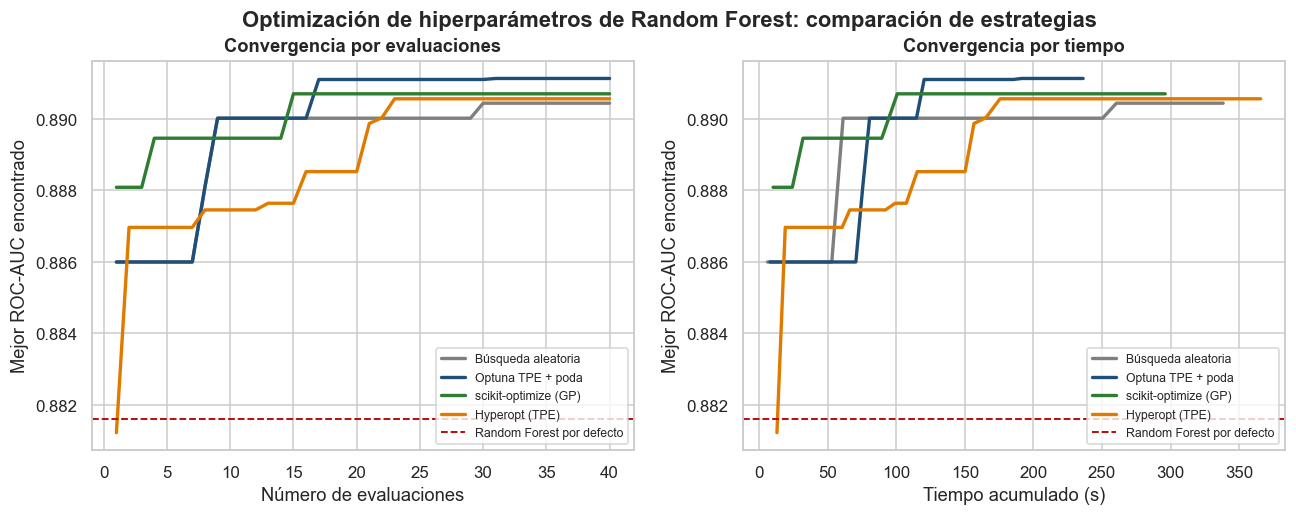

In [25]:
colores = {"Búsqueda aleatoria": GRIS, "Optuna TPE + poda": AZUL, "scikit-optimize (GP)": VERDE, "Hyperopt (TPE)": NARANJA}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for nombre, h in HISTORIAL.items():
    mejor = h["valor"].fillna(-np.inf).cummax().replace(-np.inf, np.nan)
    axes[0].plot(h["eval"], mejor, lw=2.2, color=colores[nombre], label=nombre)
    axes[1].plot(h["seg"], mejor, lw=2.2, color=colores[nombre], label=nombre)
for ax in axes:
    ax.axhline(DEFAULT_AUC, color=ROJO, ls="--", lw=1.2, label=f"{FAMILIA} por defecto")
    ax.set_ylabel("Mejor ROC-AUC encontrado"); ax.legend(fontsize=8, loc="lower right")
axes[0].set_xlabel("Número de evaluaciones"); axes[1].set_xlabel("Tiempo acumulado (s)")
axes[0].set_title("Convergencia por evaluaciones"); axes[1].set_title("Convergencia por tiempo")
fig.suptitle(f"Optimización de hiperparámetros de {FAMILIA}: comparación de estrategias", fontweight="bold")
guardar(fig, "fig11_convergencia_optimizadores")

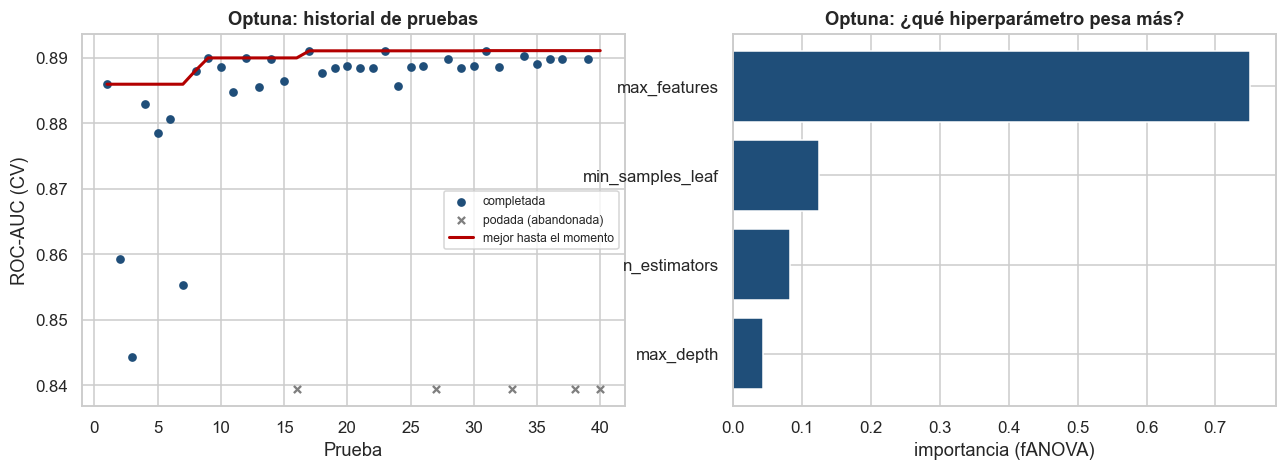

In [26]:
import optuna.importance
imp_opt = optuna.importance.get_param_importances(estudio_tpe)
h = HISTORIAL["Optuna TPE + poda"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].scatter(h.loc[~h.podada, "eval"], h.loc[~h.podada, "valor"], color=AZUL, s=22, label="completada")
axes[0].scatter(h.loc[h.podada, "eval"], np.full(h.podada.sum(), np.nanmin(h.valor) - 0.005), marker="x",
                color=GRIS, s=22, label="podada (abandonada)")
axes[0].plot(h["eval"], h["valor"].fillna(-np.inf).cummax().replace(-np.inf, np.nan), color=ROJO, lw=2, label="mejor hasta el momento")
axes[0].set_xlabel("Prueba"); axes[0].set_ylabel("ROC-AUC (CV)"); axes[0].legend(fontsize=8)
axes[0].set_title("Optuna: historial de pruebas")
s = pd.Series(imp_opt).sort_values()
axes[1].barh(s.index, s.values, color=AZUL); axes[1].set_xlabel("importancia (fANOVA)")
axes[1].set_title("Optuna: ¿qué hiperparámetro pesa más?")
guardar(fig, "fig12_optuna_historial_importancia")

## 4.1 Modelo final y evaluación en el periodo de prueba (2022-2026)

Se toman los mejores hiperparámetros de toda la comparación, se reentrena con 2003-2021 y se evalúa una sola
vez en 2022-2026. El umbral de decisión se elige con las predicciones fuera de muestra de la validación
cruzada (el que maximiza F1), no con los datos de prueba.

In [27]:
ganador = tabla_opt.index[0]
h = HISTORIAL[ganador]
MEJORES = h.loc[h["valor"].idxmax(), "params"]
print("Estrategia ganadora:", ganador); print("Mejores hiperparámetros:", MEJORES)
json.dump({"familia": FAMILIA, "estrategia": ganador, "params": MEJORES}, open(RES / "mejores_hiperparametros.json", "w"), indent=2)

def oof(pipe_fn):
    p, idx = [], []
    for itr, iva in FOLDS:
        m = pipe_fn().fit(Xtr.iloc[itr], ytr.iloc[itr])
        p.append(m.predict_proba(Xtr.iloc[iva])[:, 1]); idx.append(iva)
    return np.concatenate(p), ytr.iloc[np.concatenate(idx)].values

def umbral_f1(prob, real):
    cand = np.linspace(0.05, 0.95, 91)
    return cand[int(np.argmax([f1_score(real, prob >= c) for c in cand]))]

pipe_def = lambda: Pipeline([("prep", preprocesador(False)), ("modelo", sklearn.base.clone(MODELOS[FAMILIA]))])
pipe_opt = lambda: construir(MEJORES)
resultados_test, PROBS = [], {}
for nombre, fn in [(f"{FAMILIA} por defecto", pipe_def), (f"{FAMILIA} optimizado", pipe_opt)]:
    p_oof, r_oof = oof(fn); u = umbral_f1(p_oof, r_oof)
    modelo = fn().fit(Xtr, ytr); p = modelo.predict_proba(Xte)[:, 1]; PROBS[nombre] = p
    pred = (p >= u).astype(int)
    resultados_test.append({"Modelo": nombre, "Umbral": u, "ROC-AUC": roc_auc_score(yte, p),
                            "PR-AUC": average_precision_score(yte, p), "F1": f1_score(yte, pred),
                            "Precisión": precision_score(yte, pred), "Sensibilidad (recall)": recall_score(yte, pred),
                            "Exactitud balanceada": balanced_accuracy_score(yte, pred), "Brier": brier_score_loss(yte, p)})
    if "optimizado" in nombre:
        MODELO_FINAL, UMBRAL_FINAL, PRED_FINAL = modelo, u, pred
base = yte.mean()
resultados_test.append({"Modelo": "Línea base (azar)", "Umbral": np.nan, "ROC-AUC": 0.5, "PR-AUC": base, "F1": np.nan,
                        "Precisión": base, "Sensibilidad (recall)": np.nan, "Exactitud balanceada": 0.5,
                        "Brier": brier_score_loss(yte, np.full(len(yte), ytr.mean()))})
tabla_test = pd.DataFrame(resultados_test).set_index("Modelo")
tabla_test.to_csv(RES / "evaluacion_prueba_2022_2026.csv")
tabla_test

Estrategia ganadora: Optuna TPE + poda
Mejores hiperparámetros: {'n_estimators': 158, 'max_depth': 14, 'min_samples_leaf': 46, 'max_features': 0.7077375877582757}


,Umbral,ROC-AUC,PR-AUC,F1,Precisión,Sensibilidad (recall),Exactitud balanceada,Brier
Modelo,,,,,,,,
Random Forest por defecto,0.560,0.800,0.552,0.311,0.741,0.197,0.589,0.131
Random Forest optimizado,0.680,0.821,0.586,0.434,0.724,0.310,0.639,0.126
Línea base (azar),NaN,0.500,0.216,NaN,0.216,NaN,0.500,0.179


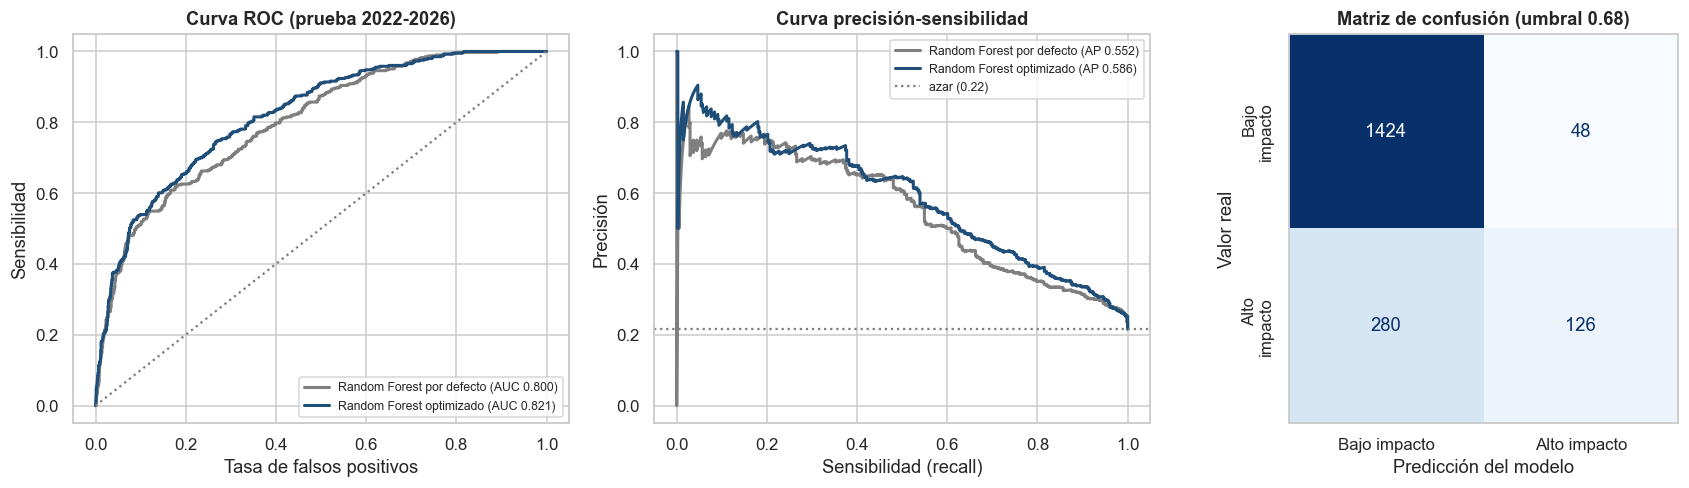

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for (nombre, p), col in zip(PROBS.items(), [GRIS, AZUL]):
    fpr, tpr, _ = roc_curve(yte, p); pr, rc, _ = precision_recall_curve(yte, p)
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{nombre} (AUC {roc_auc_score(yte, p):.3f})")
    axes[1].plot(rc, pr, color=col, lw=2, label=f"{nombre} (AP {average_precision_score(yte, p):.3f})")
axes[0].plot([0, 1], [0, 1], ":", color=GRIS); axes[1].axhline(base, ls=":", color=GRIS, label=f"azar ({base:.2f})")
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad", title="Curva ROC (prueba 2022-2026)")
axes[1].set(xlabel="Sensibilidad (recall)", ylabel="Precisión", title="Curva precisión-sensibilidad")
for ax in axes[:2]: ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
ConfusionMatrixDisplay(confusion_matrix(yte, PRED_FINAL), display_labels=["Bajo impacto", "Alto impacto"]).plot(
    ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title(f"Matriz de confusión (umbral {UMBRAL_FINAL:.2f})"); axes[2].grid(False)
axes[2].set_xlabel("Predicción del modelo"); axes[2].set_ylabel("Valor real")
axes[2].set_yticklabels(["Bajo\nimpacto", "Alto\nimpacto"], rotation=90, va="center")
fig.tight_layout()
guardar(fig, "fig13_evaluacion_prueba")

**Resultado de la optimización**

* Las cuatro estrategias mejoran el Random Forest por defecto en validación cruzada: de 0,882 a 0,890-0,891 de ROC-AUC. La mejora proviene sobre todo de **hojas más grandes** (`min_samples_leaf` entre 31 y 50) y de usar **alrededor del 70 % de las variables** en cada división (`max_features`): un bosque más regularizado generaliza mejor hacia años que no vio.
* **Optuna (TPE + poda)** logró el mejor valor (0,8911), en el menor tiempo (236 s) y con 5 pruebas abandonadas a mitad de camino por la poda. **scikit-optimize** llegó casi al mismo valor (0,8907) en solo 15 evaluaciones: el proceso gaussiano es el que aprende más rápido. **Hyperopt** (0,8906) y la **búsqueda aleatoria** (0,8904) terminaron muy cerca.
* La diferencia entre estrategias (menos de 0,001) es muy inferior a la variación entre bloques, así que con este espacio de cuatro hiperparámetros la elección del optimizador pesa poco; lo que sí cambia es **cuánto cuesta llegar**: Optuna fue un 30 % más rápido que la búsqueda aleatoria gracias a la poda.
* Según la importancia fANOVA de Optuna, `max_features` explica el 75 % de la variación del resultado; `n_estimators` casi no importa (8 %).
* **En el periodo de prueba (2022-2026)** el modelo optimizado mejora al de valores por defecto en todas las métricas: ROC-AUC de 0,800 a 0,821, PR-AUC de 0,552 a 0,586 (el azar sería 0,216) y F1 de 0,311 a 0,434.
* El desempeño en prueba es menor que en validación (0,82 frente a 0,89) y la sensibilidad con el umbral elegido es baja (31 %): en 2022-2026 solo el 21,6 % de las emergencias fue de alto impacto, frente al 31,2 % del entrenamiento, y el umbral se fijó con la proporción antigua (0,68). El modelo **ordena** bien las emergencias por riesgo (eso mide el ROC-AUC), pero el umbral conviene recalibrarlo con datos recientes. Por eso la parte prescriptiva usa el orden de riesgo y no un umbral fijo.

---
# 5. Reporting

## 5.1 Analítica descriptiva: ¿qué pasó?

In [29]:
def periodo(a):
    return "2003-2009" if a <= 2009 else "2010-2015" if a <= 2015 else "2016-2021" if a <= 2021 else "2022-2026"
kpi = puno.assign(PERIODO=puno.ANIO.map(periodo)).groupby("PERIODO").agg(
    emergencias=("COD", "size"), personas_impactadas=("PERSONAS", "sum"), damnificados=("DAMNIFICADOS", "sum"),
    fallecidos=("FALLECIDOS", "sum"), viviendas_destruidas=("VIV_DESTRUIDAS", "sum"),
    camelidos_perdidos=("CAMELIDO_PERD", "sum"), ha_cultivo_danadas=("HA_CULT_AFECT", "sum"),
    pct_alto_impacto=("ALTO", "mean"))
kpi.loc["Total"] = kpi.sum(numeric_only=True); kpi.loc["Total", "pct_alto_impacto"] = puno.ALTO.mean()
kpi.to_csv(RES / "kpi_por_periodo.csv")
kpi.style.format("{:,.0f}").format({"pct_alto_impacto": "{:.0%}"})

,emergencias,personas_impactadas,damnificados,fallecidos,viviendas_destruidas,camelidos_perdidos,ha_cultivo_danadas,pct_alto_impacto
PERIODO,,,,,,,,
2003-2009,2013.000000,613750.000000,50772.000000,57.000000,6809.000000,13167.000000,136406.000000,30%
2010-2015,1271.000000,987615.000000,50726.000000,53.000000,5152.000000,502765.000000,110967.000000,45%
2016-2021,1431.000000,819762.000000,7373.000000,31.000000,1991.000000,99261.000000,108710.200000,20%
2022-2026,1878.000000,336415.000000,7271.000000,36.000000,3430.000000,163087.000000,280401.273000,22%
Total,6593.000000,2757542.000000,116142.000000,177.000000,17382.000000,778280.000000,636484.473000,28%


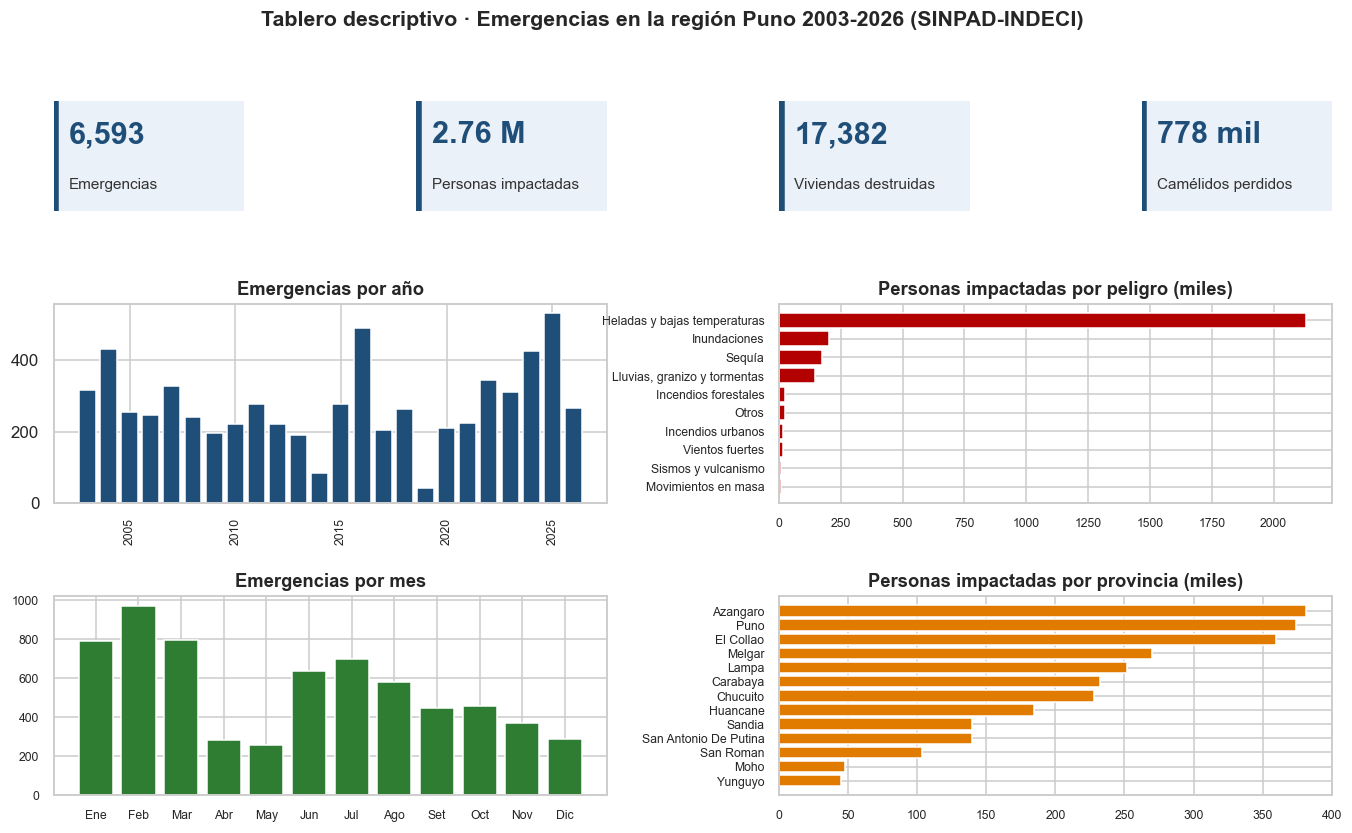

In [30]:
fig = plt.figure(figsize=(15, 8.2))
gs = fig.add_gridspec(3, 4, height_ratios=[.55, 1, 1], hspace=.55, wspace=.9)
tarjetas = [("Emergencias", f"{len(puno):,}"), ("Personas impactadas", f"{puno.PERSONAS.sum() / 1e6:,.2f} M"),
            ("Viviendas destruidas", f"{puno.VIV_DESTRUIDAS.sum():,.0f}"),
            ("Camélidos perdidos", f"{puno.CAMELIDO_PERD.sum() / 1e3:,.0f} mil")]
for i, (t, v) in enumerate(tarjetas):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color="#eaf1f8", transform=ax.transAxes))
    ax.add_patch(plt.Rectangle((0, 0), .025, 1, color=AZUL, transform=ax.transAxes))
    ax.text(.08, .62, v, fontsize=20, fontweight="bold", color=AZUL, transform=ax.transAxes)
    ax.text(.08, .2, t, fontsize=10, color="#333", transform=ax.transAxes)
ax = fig.add_subplot(gs[1, :2]); ax.bar(calidad.index, calidad.emergencias, color=AZUL)
ax.set_title("Emergencias por año"); ax.tick_params(axis="x", rotation=90, labelsize=8)
ax = fig.add_subplot(gs[1, 2:]); s = por_grupo["personas"].sort_values() / 1e3
ax.barh(s.index, s.values, color=ROJO); ax.set_title("Personas impactadas por peligro (miles)"); ax.tick_params(labelsize=8)
ax = fig.add_subplot(gs[2, :2]); s = puno.groupby("MES_NUM").size()
ax.bar([m[:3].title() for m in MESES], s.values, color=VERDE); ax.set_title("Emergencias por mes"); ax.tick_params(labelsize=8)
ax = fig.add_subplot(gs[2, 2:]); s = puno.groupby("PROV")["PERSONAS"].sum().sort_values() / 1e3
ax.barh(s.index.str.title(), s.values, color=NARANJA); ax.set_title("Personas impactadas por provincia (miles)"); ax.tick_params(labelsize=8)
fig.suptitle("Tablero descriptivo · Emergencias en la región Puno 2003-2026 (SINPAD-INDECI)", fontsize=14, fontweight="bold")
guardar(fig, "fig14_tablero_descriptivo")

**Lectura descriptiva**

* En 23 años y medio se registraron 6 593 emergencias, con 2,76 millones de personas-evento impactadas, 116 mil damnificados, 177 fallecidos, 17 mil viviendas destruidas (sin 2026) y 778 mil camélidos perdidos.
* **2010-2015** fue el periodo más dañino: con menos emergencias registradas (1 271) reunió casi un millón de personas-evento, el 45 % de emergencias de alto impacto y 503 mil camélidos perdidos.
* **2022-2026** tiene la mayor cantidad de emergencias registradas (1 878), pero menos personas por emergencia (21,6 % de alto impacto): se registran más eventos pequeños.
* El mapa del riesgo es claro: **febrero y julio** son los picos; las heladas explican la mayor parte del impacto; Azángaro, Puno y El Collao son las provincias con más personas impactadas.

## 5.2 Analítica diagnóstica: ¿por qué pasó y de qué depende?

In [31]:
def cramer_v(tabla):
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    n = tabla.values.sum(); r, k = tabla.shape
    return chi2, p, gl, np.sqrt(chi2 / (n * (min(r, k) - 1)))
filas = []
for var, nombre in [("GRUPO", "Tipo de peligro"), ("PROV", "Provincia"), ("MES_NUM", "Mes"), ("REGION", "Región natural")]:
    chi2, p, gl, v = cramer_v(pd.crosstab(puno[var], puno["ALTO"]))
    filas.append({"Variable": nombre, "Chi²": chi2, "gl": gl, "p-valor": p, "V de Cramér": v})
kw = stats.kruskal(*[g["PERSONAS"].values for _, g in puno.groupby("GRUPO")])
tabla_diag = pd.DataFrame(filas).set_index("Variable")
tabla_diag.to_csv(RES / "pruebas_diagnosticas.csv")
print(f"Kruskal-Wallis (personas impactadas según tipo de peligro): H = {kw.statistic:,.1f}, p = {kw.pvalue:.2e}")
rho, p_rho = stats.spearmanr(calidad.index[calidad.index < 2026], calidad.loc[calidad.index < 2026, "emergencias"])
print(f"Tendencia del número de emergencias 2003-2025 (Spearman): rho = {rho:.2f}, p = {p_rho:.3f}")
tabla_diag.style.format({"Chi²": "{:,.1f}", "p-valor": "{:.1e}", "V de Cramér": "{:.2f}"})

Kruskal-Wallis (personas impactadas según tipo de peligro): H = 904.1, p = 7.96e-189
Tendencia del número de emergencias 2003-2025 (Spearman): rho = 0.09, p = 0.700


,Chi²,gl,p-valor,V de Cramér
Variable,,,,
Tipo de peligro,"2,140.2",9,0.0e+00,0.57
Provincia,106.0,12,3.7e-17,0.13
Mes,907.2,11,1.8e-187,0.37
Región natural,16.8,1,4.3e-05,0.05


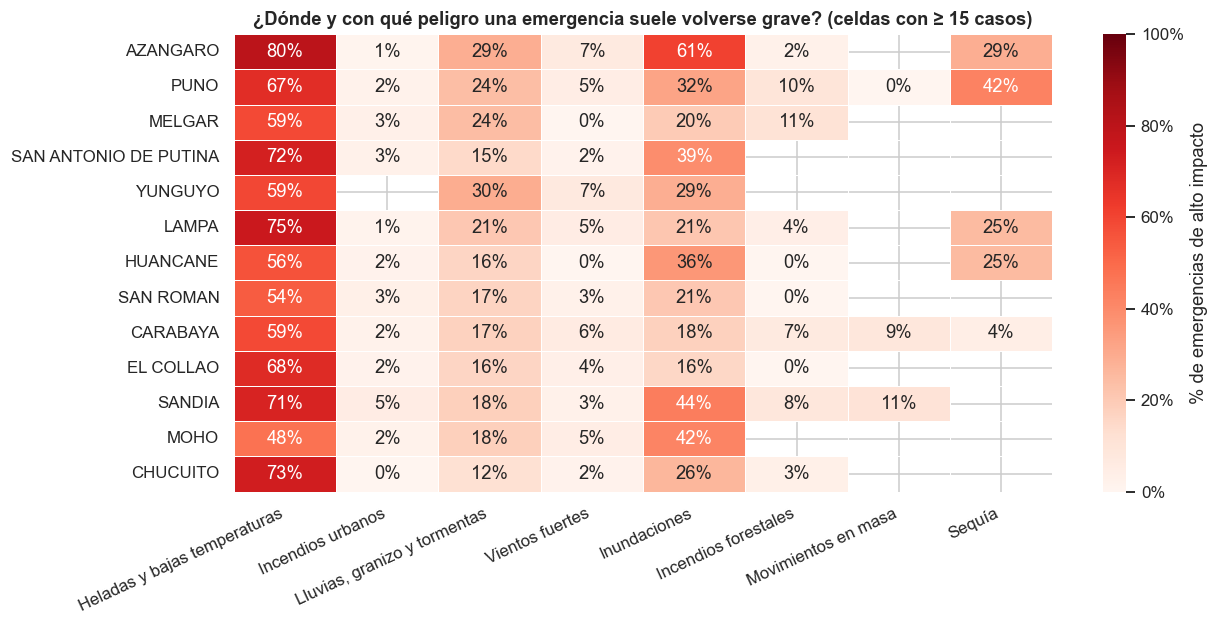

In [32]:
cruce = puno.groupby(["PROV", "GRUPO"]).agg(n=("ALTO", "size"), tasa=("ALTO", "mean")).reset_index()
cruce.loc[cruce.n < 15, "tasa"] = np.nan
mat = cruce.pivot(index="PROV", columns="GRUPO", values="tasa")[[g for g in orden if g in cruce.GRUPO.unique()]]
mat = mat.loc[:, mat.notna().sum() >= 3]
mat = mat.loc[puno.groupby("PROV")["ALTO"].mean().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(12, 5.4))
sns.heatmap(mat, cmap="Reds", annot=True, fmt=".0%", vmin=0, vmax=1, linewidths=.4, ax=ax,
            cbar_kws={"format": mtick.PercentFormatter(1), "label": "% de emergencias de alto impacto"})
ax.set_xlabel(""); ax.set_ylabel(""); ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
ax.set_title("¿Dónde y con qué peligro una emergencia suele volverse grave? (celdas con ≥ 15 casos)")
guardar(fig, "fig15_diagnostico_tasa_alto")

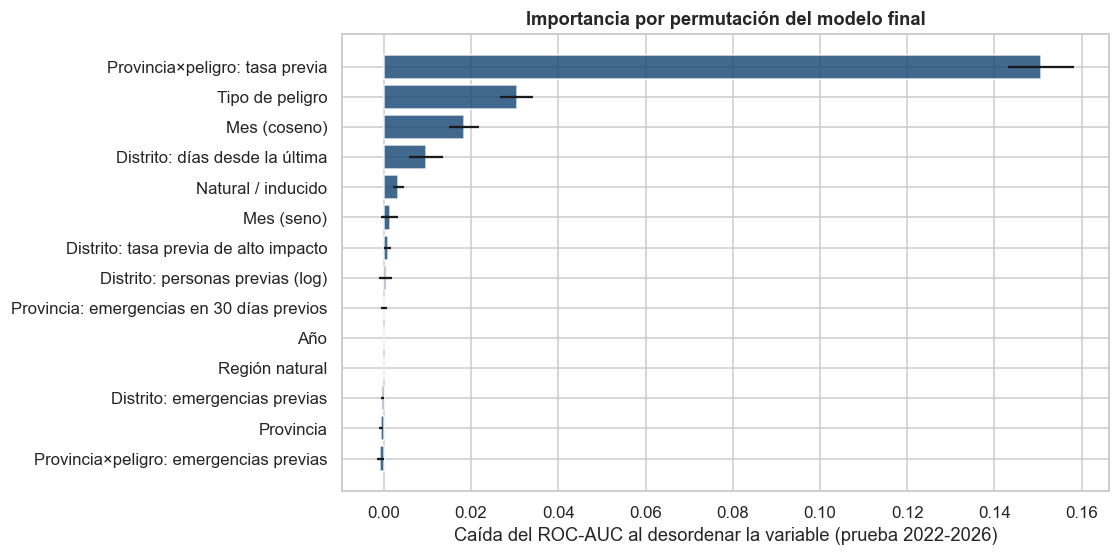

In [33]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(MODELO_FINAL, Xte, yte, scoring="roc_auc", n_repeats=15, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"media": pi.importances_mean, "de": pi.importances_std}, index=Xte.columns).sort_values("media")
etiquetas = {"GRUPO": "Tipo de peligro", "TIPO": "Natural / inducido", "REGION": "Región natural", "PROV": "Provincia",
             "MES_SIN": "Mes (seno)", "MES_COS": "Mes (coseno)", "ANIO": "Año",
             "DIST_N_PREV": "Distrito: emergencias previas", "DIST_TASA_PREV": "Distrito: tasa previa de alto impacto",
             "DIST_LOGP_PREV": "Distrito: personas previas (log)", "DIST_DIAS_ULT": "Distrito: días desde la última",
             "PG_N_PREV": "Provincia×peligro: emergencias previas", "PG_TASA_PREV": "Provincia×peligro: tasa previa",
             "PROV_30D": "Provincia: emergencias en 30 días previos"}
imp.index = imp.index.map(etiquetas)
imp.to_csv(RES / "importancia_permutacion.csv")
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.barh(imp.index, imp["media"], xerr=imp["de"], color=AZUL, alpha=.85)
ax.set_xlabel("Caída del ROC-AUC al desordenar la variable (prueba 2022-2026)")
ax.set_title("Importancia por permutación del modelo final")
guardar(fig, "fig16_importancia_permutacion")

**Lectura diagnóstica**

* El **tipo de peligro** es lo que más explica que una emergencia sea grave (chi², V de Cramér = 0,57, asociación fuerte), seguido del **mes** (V = 0,37). La provincia (V = 0,13) y la región natural (V = 0,05) pesan mucho menos por sí solas. Las personas impactadas difieren de forma muy significativa entre peligros (Kruskal-Wallis H = 904, p < 0,001).
* No hay una tendencia significativa en el número de emergencias por año entre 2003 y 2025 (Spearman ρ = 0,09, p = 0,70): las subidas y bajadas responden a años concretos y a cambios en el registro más que a una tendencia sostenida.
* El mismo peligro no golpea igual en todas partes: en **Azángaro** el 80 % de las heladas registradas supera las 100 personas, en **Lampa** el 75 % y en **Chucuito** el 73 %, frente al 48 % en **Moho** y el 54 % en **San Román** (más urbana). La vulnerabilidad local cuenta.
* El modelo confirma esta lectura: la variable más importante, con mucha diferencia, es la **tasa histórica de alto impacto de ese mismo peligro en esa provincia** (su permutación hace caer el ROC-AUC en 0,15), seguida del tipo de peligro y del mes. La historia del lugar frente a cada peligro es la mejor pista de lo que puede pasar.

## 5.3 Analítica predictiva: ¿qué puede pasar?

Además del desempeño en 2022-2026 (paso 4), el modelo se usa para construir una **matriz de riesgo por
provincia y mes**. Para cada celda se calcula el número esperado de emergencias de alto impacto en un año:

$$\text{alto impacto esperado}_{p,m} = \underbrace{\overline{\text{emergencias}}_{p,m}}_{\text{promedio 2021-2025}} \times \underbrace{\hat{P}(\text{alto}\mid p, m)}_{\text{probabilidad media del modelo}}$$

La probabilidad media de cada celda se suaviza hacia la de la provincia (peso de 5 casos) para que las celdas con
pocas emergencias no tengan valores extremos.

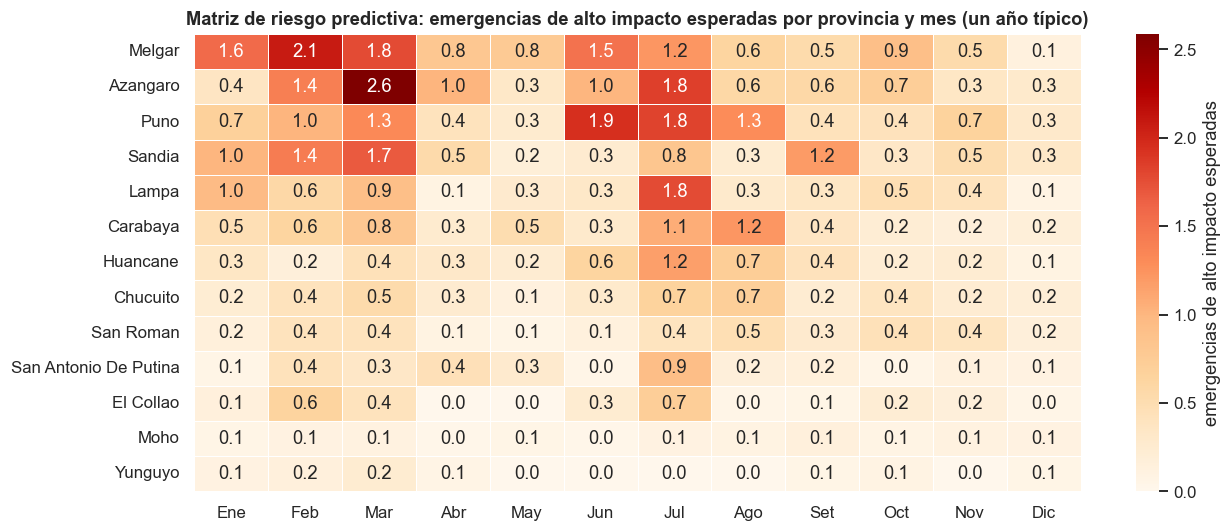

Total esperado en un año: 75.8 emergencias de alto impacto


In [34]:
prob_todo = MODELO_FINAL.predict_proba(X)[:, 1]
df["PROB"] = prob_todo
rec = df[df.ANIO.between(2021, 2025)]
frec = rec.groupby(["PROV", "MES_NUM"]).size().unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0) / 5
celda = rec.groupby(["PROV", "MES_NUM"])["PROB"].agg(["sum", "size"])
prov_media = rec.groupby("PROV")["PROB"].mean()
k = 5
psuav = ((celda["sum"] + k * prov_media.reindex(celda.index.get_level_values(0)).values) / (celda["size"] + k)).unstack()
psuav = psuav.reindex(columns=range(1, 13)).T.fillna(prov_media).T
riesgo = (frec * psuav).fillna(0)
riesgo = riesgo.loc[riesgo.sum(axis=1).sort_values(ascending=False).index]
riesgo.to_csv(RES / "matriz_riesgo_provincia_mes.csv")

fig, ax = plt.subplots(figsize=(13, 5.4))
sns.heatmap(riesgo, cmap="OrRd", annot=True, fmt=".1f", linewidths=.4, ax=ax,
            xticklabels=[m[:3].title() for m in MESES], yticklabels=riesgo.index.str.title(),
            cbar_kws={"label": "emergencias de alto impacto esperadas"})
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Matriz de riesgo predictiva: emergencias de alto impacto esperadas por provincia y mes (un año típico)")
guardar(fig, "fig17_matriz_riesgo")
print("Total esperado en un año:", round(riesgo.values.sum(), 1), "emergencias de alto impacto")

**Lectura predictiva**

* En un año típico se esperan unas **76 emergencias de alto impacto** en la región.
* **Melgar** (12,5), **Azángaro** (11,1) y **Puno** (10,6) son las provincias con más casos graves esperados, seguidas de **Sandía** (8,6). En el otro extremo, Moho y Yunguyo esperan alrededor de un caso grave al año.
* El riesgo cambia de lugar según la temporada. En **lluvias (diciembre-marzo)** encabezan Melgar (5,6), Azángaro (4,7) y Sandía (4,4); la celda más crítica del año es **Azángaro en marzo** (2,6). En **heladas (mayo-setiembre)** encabezan Puno (5,8), Melgar (4,7) y Azángaro (4,4), con picos en junio-julio en Puno, Lampa y Azángaro.
* Esta matriz es la entrada del modelo prescriptivo: dice cuánta necesidad esperar, dónde y cuándo.

## 5.4 Analítica prescriptiva: ¿qué conviene hacer?

Se proponen dos decisiones apoyadas en los resultados anteriores.

### A. Regla de priorización de la evaluación de daños (EDAN)

Los equipos evaluadores son pocos. Si cada vez que llega un reporte se ordena por la probabilidad del modelo y se
atiende primero a las de mayor riesgo, ¿qué porcentaje de las emergencias graves se cubre según la capacidad?

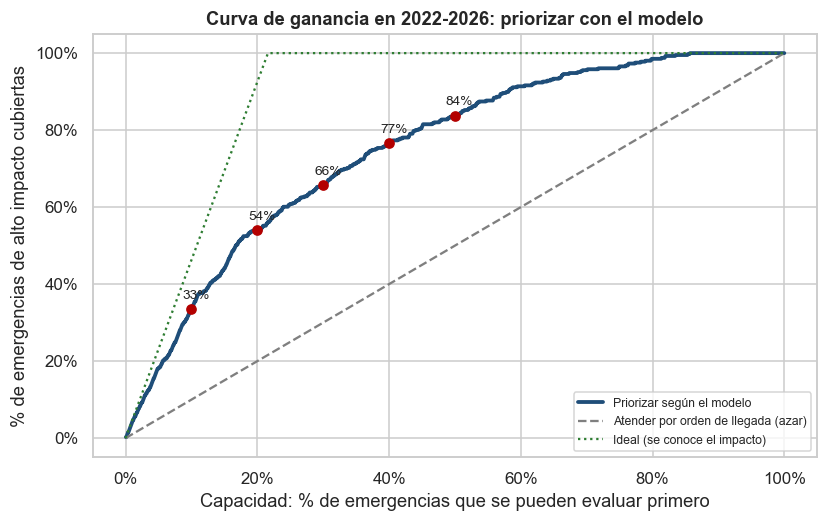

,% de alto impacto cubierto
evaluar primero el 10%,33%
evaluar primero el 20%,54%
evaluar primero el 30%,66%
evaluar primero el 40%,77%
evaluar primero el 50%,84%


In [35]:
p_final = PROBS[f"{FAMILIA} optimizado"]
orden_p = np.argsort(-p_final); y_ord = yte.values[orden_p]
capacidad = np.arange(1, len(y_ord) + 1) / len(y_ord)
captura = np.cumsum(y_ord) / y_ord.sum()
puntos = {c: captura[int(c * len(y_ord)) - 1] for c in [.1, .2, .3, .4, .5]}

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(capacidad, captura, color=AZUL, lw=2.5, label="Priorizar según el modelo")
ax.plot([0, 1], [0, 1], ls="--", color=GRIS, label="Atender por orden de llegada (azar)")
ax.plot([0, base, 1], [0, 1, 1], ls=":", color=VERDE, label="Ideal (se conoce el impacto)")
for c, v in puntos.items():
    ax.scatter(c, v, color=ROJO, zorder=3); ax.annotate(f"{v:.0%}", (c, v), textcoords="offset points", xytext=(-6, 7), fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Capacidad: % de emergencias que se pueden evaluar primero")
ax.set_ylabel("% de emergencias de alto impacto cubiertas")
ax.set_title("Curva de ganancia en 2022-2026: priorizar con el modelo"); ax.legend(fontsize=8, loc="lower right")
guardar(fig, "fig18_curva_ganancia_priorizacion")
pd.Series(puntos, name="% de alto impacto cubierto").rename(lambda c: f"evaluar primero el {c:.0%}").to_frame().style.format("{:.0%}")

**Regla prescriptiva A: evaluar primero lo que el modelo marca como más riesgoso**

Si cada día se ordenan los reportes por la probabilidad del modelo y se evalúa primero el 20 % de mayor riesgo, se cubre el **54 %** de las emergencias graves; con el 30 %, el **66 %**, y con la mitad, el **84 %**. Atendiendo por orden de llegada, esos porcentajes serían 20 %, 30 % y 50 %. Con la misma cantidad de evaluadores, se llega antes a casi el triple de emergencias graves cuando la capacidad es escasa (10 % de capacidad: 33 % de casos graves cubiertos frente a 10 %).

### B. Pre-posicionamiento de kits de ayuda humanitaria (programación lineal con PuLP)

Antes de cada temporada, la región decide cuántos kits (abrigo, techo, alimentos) dejar en cada provincia.
Se formula un modelo de programación lineal:

**Datos**

* $d_p$: kits que se espera necesitar en la provincia $p$ durante la temporada = alto impacto esperado en la
  temporada (matriz de riesgo) × mediana de personas impactadas en las emergencias graves de esa provincia
  (2016-2025) ÷ 4 personas por kit (supuesto: un kit por familia).
* $w_p = 1 + $ proporción de damnificados entre las personas impactadas de la provincia (las provincias donde más
  gente pierde su vivienda pesan más).
* $c_p$: distancia aproximada por carretera desde un almacén central supuesto en Juliaca (km).
* $S$: stock disponible de kits.

**Variables:** la asignación de cada provincia se divide en tres tramos, $x_p = y_{p1} + y_{p2} + y_{p3}$, cada
uno de hasta un tercio de su demanda ($0 \le y_{pk} \le d_p/3$). El primer tercio cubre las necesidades más
urgentes y vale el triple; el segundo, el doble; el tercero, lo normal ($v_1=3, v_2=2, v_3=1$). Así cada kit
adicional en una misma provincia rinde un poco menos que el anterior (rendimientos decrecientes) y el modelo no
deja a una provincia en cero mientras otra recibe todo.

$$\min \sum_p \sum_{k=1}^{3} w_p\,v_k\left(\tfrac{d_p}{3} - y_{pk}\right) + 0.001\sum_p c_p\,x_p
\qquad \text{s.a.}\quad \sum_p x_p \le S,\qquad 0 \le y_{pk} \le \tfrac{d_p}{3}$$

El primer término es la necesidad no cubierta, ponderada; la segunda suma pesa muy poco y solo desempata a favor
de las provincias más cercanas. El precio sombra de la restricción de stock indica cuánta necesidad ponderada
se deja sin cubrir por cada kit que falta. Se resuelve para las dos temporadas de Puno y para tres
niveles de stock (50 %, 75 % y 100 % de la demanda total $D$).

In [36]:
DIST_JULIACA = {"SAN ROMAN": 10, "LAMPA": 34, "PUNO": 44, "AZANGARO": 60, "MELGAR": 97, "EL COLLAO": 98,
                "HUANCANE": 100, "SAN ANTONIO DE PUTINA": 113, "CHUCUITO": 123, "MOHO": 137, "YUNGUYO": 175,
                "CARABAYA": 191, "SANDIA": 262}   # km aproximados por carretera hasta la capital provincial
PERSONAS_POR_KIT = 4
TEMPORADAS = {"Lluvias (dic-mar)": [12, 1, 2, 3], "Heladas (may-set)": [5, 6, 7, 8, 9]}

graves = puno[(puno.ALTO == 1) & puno.ANIO.between(2016, 2025)]
mediana_graves = graves.groupby("PROV")["PERSONAS"].median().reindex(riesgo.index).fillna(graves["PERSONAS"].median())
prov_tot = puno.groupby("PROV")[["DAMNIFICADOS", "PERSONAS"]].sum()
peso = 1 + (prov_tot["DAMNIFICADOS"] / prov_tot["PERSONAS"]).reindex(riesgo.index)

VALOR_TRAMO = {1: 3, 2: 2, 3: 1}
def asignar(demanda, S):
    prob = pulp.LpProblem("prepos_kits", pulp.LpMinimize)
    y = {(p, k): pulp.LpVariable(f"y_{i}_{k}", lowBound=0, upBound=demanda[p] / 3)
         for i, p in enumerate(demanda.index) for k in VALOR_TRAMO}
    x = {p: pulp.lpSum(y[p, k] for k in VALOR_TRAMO) for p in demanda.index}
    prob += (pulp.lpSum(peso[p] * v * (demanda[p] / 3 - y[p, k]) for p in demanda.index for k, v in VALOR_TRAMO.items())
             + 0.001 * pulp.lpSum(DIST_JULIACA[p] * x[p] for p in demanda.index))
    prob += pulp.lpSum(x.values()) <= S, "stock"
    prob.solve(pulp.PULP_CBC_CMD(msg=False))
    asign = pd.Series({p: pulp.value(x[p]) for p in demanda.index})
    return asign, pulp.LpStatus[prob.status], prob.constraints["stock"].pi, pulp.value(prob.objective)

def no_cubierto(dem, a):
    """Necesidad ponderada no cubierta (con los mismos tramos del modelo), como proporción del total."""
    total = (peso * dem).sum() * 2      # suma de v_k / 3 = 2
    cub = sum(peso[p] * sum(v * min(max(a[p] - (k - 1) * dem[p] / 3, 0), dem[p] / 3) for k, v in VALOR_TRAMO.items())
              for p in dem.index)
    return 1 - cub / total

salidas, demandas, sombra = [], {}, {}
for temp, meses in TEMPORADAS.items():
    dem = (riesgo[meses].sum(axis=1) * mediana_graves / PERSONAS_POR_KIT).round()
    demandas[temp] = dem
    for nivel in [0.5, 0.75, 1.0]:
        S = round(nivel * dem.sum())
        a, estado, pi, z = asignar(dem, S)
        sombra[(temp, nivel)] = pi
        salidas.append(pd.DataFrame({"temporada": temp, "stock": f"{nivel:.0%}", "provincia": dem.index,
                                     "demanda": dem.values, "asignado": a.round().values,
                                     "cobertura": (a / dem).values}))
        print(f"{temp:<18} stock {nivel:>4.0%} = {S:>6,} kits · {estado} · necesidad no cubierta {no_cubierto(dem, a):.0%}"
              f" · precio sombra del stock = {abs(pi):.2f}")
plan = pd.concat(salidas, ignore_index=True)
plan.to_csv(RES / "plan_prepos_kits.csv", index=False)
pd.DataFrame(demandas).astype(int).assign(peso_w=peso.round(2), km_desde_juliaca=pd.Series(DIST_JULIACA))

Lluvias (dic-mar)  stock  50% =  2,444 kits · Optimal · necesidad no cubierta 33% · precio sombra del stock = 1.97
Lluvias (dic-mar)  stock  75% =  3,665 kits · Optimal · necesidad no cubierta 13% · precio sombra del stock = 0.99
Lluvias (dic-mar)  stock 100% =  4,887 kits · Optimal · necesidad no cubierta 0% · precio sombra del stock = 0.00
Heladas (may-set)  stock  50% =  3,151 kits · Optimal · necesidad no cubierta 33% · precio sombra del stock = 1.99
Heladas (may-set)  stock  75% =  4,726 kits · Optimal · necesidad no cubierta 13% · precio sombra del stock = 0.99
Heladas (may-set)  stock 100% =  6,302 kits · Optimal · necesidad no cubierta 0% · precio sombra del stock = 0.00


,Lluvias (dic-mar),Heladas (may-set),peso_w,km_desde_juliaca
PROV,,,,
MELGAR,914,770,1.030,97
AZANGARO,642,600,1.050,60
PUNO,521,902,1.030,44
SANDIA,240,147,1.070,262
LAMPA,535,631,1.040,34
CARABAYA,631,1047,1.060,191
HUANCANE,319,966,1.050,100
CHUCUITO,298,440,1.040,123
SAN ROMAN,230,271,1.030,10


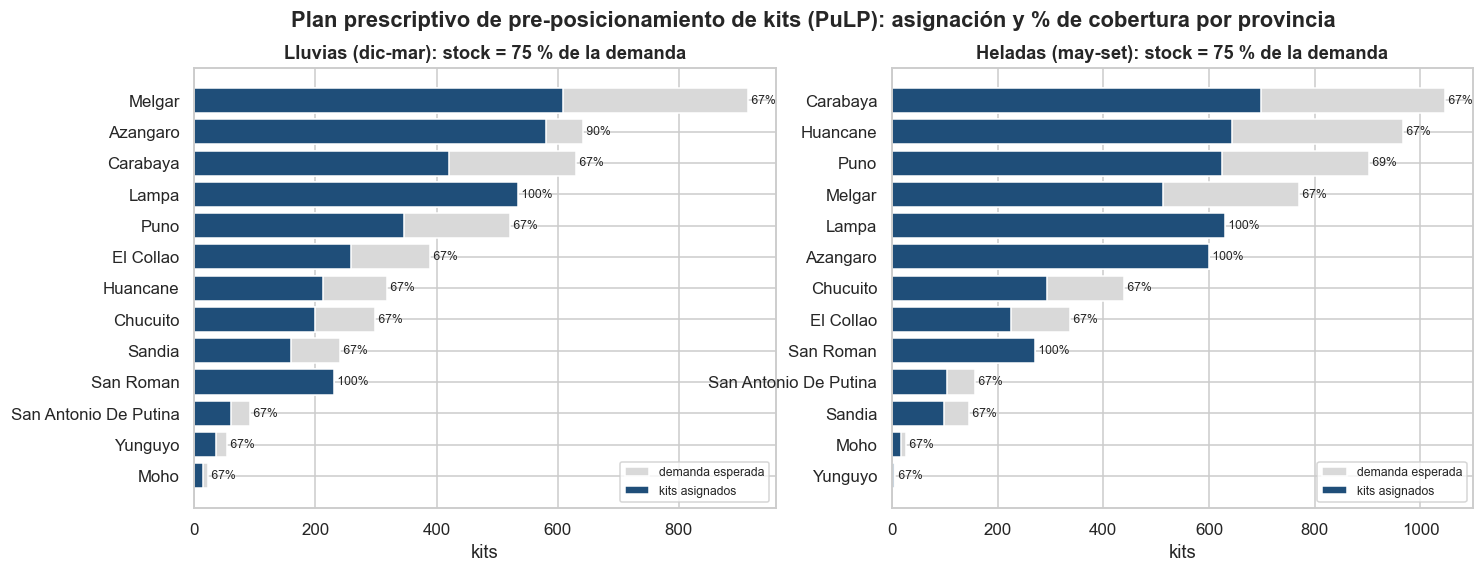

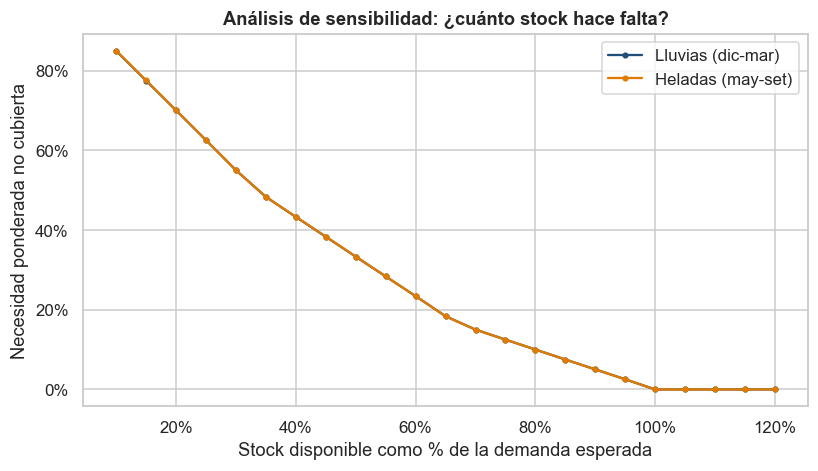

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=False)
for ax, temp in zip(axes, TEMPORADAS):
    t = plan[(plan.temporada == temp) & (plan.stock == "75%")].set_index("provincia").sort_values("demanda")
    ax.barh(t.index.str.title(), t["demanda"], color="#d9d9d9", label="demanda esperada")
    ax.barh(t.index.str.title(), t["asignado"], color=AZUL, label="kits asignados")
    for i, (d, c) in enumerate(zip(t["demanda"], t["cobertura"])):
        ax.text(d, i, f" {c:.0%}", va="center", fontsize=8)
    ax.set_title(f"{temp}: stock = 75 % de la demanda"); ax.set_xlabel("kits"); ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Plan prescriptivo de pre-posicionamiento de kits (PuLP): asignación y % de cobertura por provincia", fontweight="bold")
guardar(fig, "fig19_plan_kits")

niveles = np.linspace(0.1, 1.2, 23)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for temp, col in zip(TEMPORADAS, [AZUL, NARANJA]):
    dem = demandas[temp]; nc = []
    for n in niveles:
        a, *_ = asignar(dem, round(n * dem.sum()))
        nc.append(no_cubierto(dem, a))
    ax.plot(niveles, nc, marker="o", ms=3, color=col, label=temp)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Stock disponible como % de la demanda esperada"); ax.set_ylabel("Necesidad ponderada no cubierta")
ax.set_title("Análisis de sensibilidad: ¿cuánto stock hace falta?"); ax.legend()
guardar(fig, "fig20_sensibilidad_stock")

**Regla prescriptiva B: cuántos kits dejar en cada provincia**

* La demanda esperada es de unos **4 900 kits en la temporada de lluvias** y **6 300 en la de heladas**: las heladas exigen un 29 % más de abastecimiento.
* Con un stock del **75 %** de la demanda, el modelo cubre a todas las provincias al menos en dos tercios y deja solo un **13 %** de necesidad ponderada sin cubrir. Con el **50 %**, la necesidad no cubierta sube al **33 %**.
* El último tercio de la demanda se completa primero en **San Román, Lampa y Azángaro**. Los pesos de vulnerabilidad de las provincias son muy parecidos (entre 1,02 y 1,12), así que en ese último tramo decide la distancia al almacén de Juliaca: son las provincias más cercanas y cuesta menos llegar a ellas.
* El **precio sombra** del stock es de alrededor de 2 cuando el stock es del 50 % y de 1 cuando es del 75 %: cada kit adicional rinde el doble cuando el stock es escaso. La curva de sensibilidad muestra que pasar del 50 % al 75 % reduce la necesidad no cubierta a menos de la mitad, mientras que ir del 75 % al 100 % cuesta lo mismo y rinde menos.
* **Recomendación:** pre-posicionar al menos el 75 % de la demanda esperada antes de **noviembre** (lluvias, con prioridad en Melgar, Azángaro, Carabaya y Lampa) y antes de **abril** (heladas, con prioridad en Carabaya, Huancané, Puno y Melgar).

---
# Conclusiones

1. **Dataset.** El SINPAD es una fuente rica, pero con problemas de registro que hay que declarar: subregistro en 2014 y 2019, pérdida del registro de la ayuda humanitaria desde 2012 y un error en la columna de viviendas destruidas del archivo de 2026. Sin esa revisión, varias conclusiones habrían sido falsas.
2. **EDA.** Las heladas son el problema central de Puno: el 29 % de las emergencias, pero el 77 % de las personas impactadas y el 76 % de los camélidos perdidos. El riesgo tiene dos temporadas (diciembre-marzo y mayo-agosto) y está concentrado en pocos distritos.
3. **Modelos.** Con información disponible al momento del reporte (peligro, lugar, mes e historia del lugar), un Random Forest distingue las emergencias de alto impacto con un ROC-AUC de 0,88 en validación temporal.
4. **Optimización.** Optuna, scikit-optimize e Hyperopt mejoraron el modelo de forma parecida (0,882 a 0,891 en validación; 0,800 a 0,821 en prueba). Optuna fue el más eficiente gracias a la poda; scikit-optimize, el que convergió en menos evaluaciones.
5. **Reporting.** La analítica descriptiva identifica qué y cuándo; la diagnóstica muestra que el tipo de peligro y la vulnerabilidad histórica de cada provincia explican la gravedad; la predictiva cuantifica unas 76 emergencias graves esperadas por año, con Melgar, Azángaro y Puno a la cabeza; y la prescriptiva traduce todo en dos decisiones: priorizar las evaluaciones con el modelo y pre-posicionar al menos el 75 % de los kits antes de cada temporada.

**Limitaciones.** La meta (≥ 100 personas) es un umbral elegido; el modelo pierde desempeño en los años recientes porque cambió la proporción de casos graves; las distancias y el tamaño del kit son supuestos, y las personas-evento no equivalen a personas distintas.

In [38]:
print("Figuras guardadas:", len(list(FIG.glob("*.png"))), "· Tablas:", len(list(RES.glob("*"))))

Figuras guardadas: 20 · Tablas: 15


## Tablero interactivo

Los resultados de este cuaderno se exportan a la carpeta `shiny/data` y alimentan el tablero publicado en https://mlnp.shinyapps.io/emergencias-puno/. Sus pestañas siguen el orden de la analítica: Resumen y Mapa para la descriptiva, Diagnóstico para la diagnóstica, Modelo y Predicción para la predictiva, y Prescripción para la prescriptiva, donde se puede mover la capacidad de evaluación y el stock de kits para observar cómo cambia la recomendación.